# Generative Deep Learning-Driven Sustainable Composite Material Discovery and Physics- Guided Structural Performance Prediction

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rajsharg/compositelab-multi-modal-fibre-composite-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'compositelab-multi-modal-fibre-composite-dataset' dataset.
Path to dataset files: /kaggle/input/compositelab-multi-modal-fibre-composite-dataset


In [ ]:

import kagglehub
import os

# Download dataset
path = kagglehub.dataset_download(
    "rajsharg/compositelab-multi-modal-fibre-composite-dataset"
)

print("Dataset Path:", path)
print("\nDataset Structure:\n")

for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)
    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    subindent = "    " * (level + 1)
    for file in sorted(files):
        print(f"{subindent}{file}")


Dataset Path: /root/.cache/kagglehub/datasets/rajsharg/compositelab-multi-modal-fibre-composite-dataset/versions/2

Dataset Structure:

2/
    CompositeLab Multi-Modal Fibre Composite Dataset/
        MANIFEST.csv
        README.md
        4_multifidelity_curves/
            twill_force_stroke_curves/
                0C1.csv
                0C2.csv
                0C3.csv
                0C4.csv
                0T1.csv
                0T2.csv
                0T3.csv
                0T4.csv
                45T1.csv
                45T2.csv
                45T3.csv
                45T4.csv
                45T5.csv
                45T6.csv
            twill_specimen_photos/
                0C1.jpg
                0T-OM.jpg
                0T4.jpg
                45T-OM.jpg
                45T4.jpg
        3_graph_topological/
            README.md
        2_visual_spatial/
            fiber_ellipses_all.parquet
            ellipse_records/
                0.0003,0.9969,0.0028.csv
        

# PHASE 1: MULTI-MODAL DATA INGESTION AND HARMONIZATION

In [ ]:

# ================================================================
# PHASE 1: MULTI-MODAL DATA INGESTION AND HARMONIZATION
# ================================================================

import os
import glob
import warnings
import numpy as np
import pandas as pd
import kagglehub

warnings.filterwarnings("ignore")

# Optional libraries
try:
    import cv2
    CV_AVAILABLE = True
except ImportError:
    CV_AVAILABLE = False

try:
    import pyarrow.parquet as pq
    PARQUET_AVAILABLE = True
except ImportError:
    PARQUET_AVAILABLE = False

try:
    from PIL import Image
    IMAGE_AVAILABLE = True
except ImportError:
    IMAGE_AVAILABLE = False

try:
    from pypdf import PdfReader
    PDF_AVAILABLE = True
except ImportError:
    PDF_AVAILABLE = False


# ================================================================
# 1. DATASET DOWNLOAD
# ================================================================

print("\nPHASE 1: MULTI-MODAL DATA INGESTION")
print("=" * 80)

DATASET_PATH = kagglehub.dataset_download(
    "rajsharg/compositelab-multi-modal-fibre-composite-dataset"
)

print("Dataset downloaded:", DATASET_PATH)


# ================================================================
# 2. MODALITY DIRECTORY DEFINITIONS
# ================================================================

MODALITY_DIRS = {
    "1_tabular_scalar": [
        "1_tabular_scalar",
        "hawk_csv",
        "twill_processed"
    ],

    "2_visual_spatial": [
        "2_visual_spatial",
        "ellipse_records",
        "microstructure_results"
    ],

    "3_graph_topological": [
        "3_graph_topological",
        "ellipse_records"
    ],

    "4_multifidelity_curves": [
        "4_multifidelity_curves",
        "twill_force_stroke_curves",
        "twill_specimen_photos"
    ]
}

EXTENSIONS = {
    "tabular": [".csv", ".xlsx", ".xls"],
    "visual": [".parquet", ".png", ".jpg", ".jpeg", ".pdf"],
    "graph": [".csv", ".parquet", ".xlsx"],
    "curves": [".csv", ".xlsx"],
    "photos": [".jpg", ".jpeg", ".png"]
}


# ================================================================
# 3. AUTOMATIC FILE DISCOVERY
# ================================================================

all_files = []

for root, dirs, files in os.walk(DATASET_PATH):

    for filename in files:

        full_path = os.path.join(root, filename)

        all_files.append({
            "filename": filename,
            "path": full_path,
            "folder": os.path.basename(root),
            "extension": os.path.splitext(filename)[1].lower(),
            "size_bytes": os.path.getsize(full_path)
        })

file_manifest = pd.DataFrame(all_files)

print("\nTotal files discovered:", len(file_manifest))


# ================================================================
# 4. MODALITY CLASSIFICATION
# ================================================================

def classify_modality(file_path):

    normalized_path = file_path.replace("\\", "/").lower()
    filename = os.path.basename(normalized_path)
    extension = os.path.splitext(filename)[1]

    if "twill_force_stroke_curves" in normalized_path:
        return "4_multifidelity_curves"

    if "twill_specimen_photos" in normalized_path:
        return "4_multifidelity_curves"

    if "ellipse_records" in normalized_path:
        return "2_visual_spatial"

    if "microstructure_results" in normalized_path:
        return "2_visual_spatial"

    if "hawk_csv" in normalized_path:
        return "1_tabular_scalar"

    if "twill_processed" in normalized_path:
        return "1_tabular_scalar"

    if "1_tabular_scalar" in normalized_path:
        return "1_tabular_scalar"

    if "2_visual_spatial" in normalized_path:
        return "2_visual_spatial"

    if "3_graph_topological" in normalized_path:
        return "3_graph_topological"

    if "4_multifidelity_curves" in normalized_path:
        return "4_multifidelity_curves"

    return "unclassified"


file_manifest["modality"] = file_manifest["path"].apply(
    classify_modality
)

print("\nMODALITY FILE DISTRIBUTION")
print(file_manifest["modality"].value_counts())


# ================================================================
# 5. INITIALIZE MULTI-MODAL DATA CONTAINERS
# ================================================================

tabular_data = {}
visual_data = {}
graph_data = {}
curve_data = {}

visual_features = []
graph_features = []
curve_features = []

ingestion_errors = []


# ================================================================
# 6. TABULAR SCALAR DATA INGESTION
# ================================================================

print("\n[1] TABULAR / SCALAR DATA INGESTION")
print("-" * 80)

tabular_files = file_manifest[
    file_manifest["modality"] == "1_tabular_scalar"
]

for _, row in tabular_files.iterrows():

    file_path = row["path"]
    filename = row["filename"]
    extension = row["extension"]

    try:

        if extension == ".csv":
            df = pd.read_csv(file_path)

        elif extension in [".xlsx", ".xls"]:
            df = pd.read_excel(file_path)

        else:
            continue

        tabular_data[filename] = df

        print(
            f"Loaded: {filename} | "
            f"Shape: {df.shape}"
        )

    except Exception as e:
        ingestion_errors.append((filename, str(e)))


# ================================================================
# 7. VISUAL / SPATIAL DATA INGESTION
# ================================================================

print("\n[2] VISUAL / SPATIAL DATA INGESTION")
print("-" * 80)

visual_files = file_manifest[
    file_manifest["modality"] == "2_visual_spatial"
]

for _, row in visual_files.iterrows():

    file_path = row["path"]
    filename = row["filename"]
    extension = row["extension"]

    try:

        if extension == ".parquet":

            df = pd.read_parquet(file_path)

            visual_data[filename] = df

            visual_features.append({
                "filename": filename,
                "type": "parquet",
                "rows": len(df),
                "columns": len(df.columns)
            })

            print("Parquet loaded:", filename, df.shape)

        elif extension == ".csv":

            df = pd.read_csv(file_path)

            visual_data[filename] = df

            visual_features.append({
                "filename": filename,
                "type": "csv",
                "rows": len(df),
                "columns": len(df.columns)
            })

        elif extension in [".png", ".jpg", ".jpeg"]:

            if IMAGE_AVAILABLE:

                img = Image.open(file_path).convert("RGB")

                image_array = np.array(img)

                feature = {
                    "filename": filename,
                    "width": img.width,
                    "height": img.height,
                    "mean_red": image_array[:, :, 0].mean(),
                    "mean_green": image_array[:, :, 1].mean(),
                    "mean_blue": image_array[:, :, 2].mean()
                }

                if CV_AVAILABLE:

                    gray = cv2.cvtColor(
                        image_array,
                        cv2.COLOR_RGB2GRAY
                    )

                    feature["grayscale_mean"] = gray.mean()
                    feature["grayscale_std"] = gray.std()
                    feature["edge_density"] = (
                        cv2.Canny(gray, 100, 200) > 0
                    ).mean()

                visual_features.append(feature)

                print(
                    f"Image processed: {filename} "
                    f"| Dimensions: {img.size}"
                )

        elif extension == ".pdf":

            pages = None

            if PDF_AVAILABLE:
                pdf = PdfReader(file_path)
                pages = len(pdf.pages)

            visual_features.append({
                "filename": filename,
                "type": "pdf",
                "pages": pages
            })

            print("PDF detected:", filename)

    except Exception as e:
        ingestion_errors.append((filename, str(e)))


# ================================================================
# 8. GRAPH / TOPOLOGICAL DATA INGESTION
# ================================================================

print("\n[3] GRAPH / TOPOLOGICAL DATA INGESTION")
print("-" * 80)

graph_files = file_manifest[
    file_manifest["modality"] == "3_graph_topological"
]

for _, row in graph_files.iterrows():

    file_path = row["path"]
    filename = row["filename"]
    extension = row["extension"]

    try:

        if extension == ".csv":
            df = pd.read_csv(file_path)

        elif extension == ".parquet":
            df = pd.read_parquet(file_path)

        elif extension in [".xlsx", ".xls"]:
            df = pd.read_excel(file_path)

        else:
            continue

        graph_data[filename] = df

        print(
            f"Graph source loaded: {filename} "
            f"| Shape: {df.shape}"
        )

    except Exception as e:
        ingestion_errors.append((filename, str(e)))


# ================================================================
# 9. MULTI-FIDELITY FORCE-STROKE CURVE INGESTION
# ================================================================

print("\n[4] MULTI-FIDELITY MECHANICAL DATA INGESTION")
print("-" * 80)

curve_files = file_manifest[
    file_manifest["modality"] == "4_multifidelity_curves"
]

for _, row in curve_files.iterrows():

    file_path = row["path"]
    filename = row["filename"]
    extension = row["extension"]

    try:

        if extension == ".csv":

            df = pd.read_csv(file_path)

            curve_data[filename] = df

            numeric_df = df.select_dtypes(
                include=[np.number]
            )

            feature = {
                "specimen_id": os.path.splitext(filename)[0],
                "filename": filename,
                "rows": len(df),
                "columns": len(df.columns)
            }

            for col in numeric_df.columns:

                values = numeric_df[col].dropna()

                if len(values) > 0:

                    feature[f"{col}_mean"] = values.mean()
                    feature[f"{col}_std"] = values.std()
                    feature[f"{col}_min"] = values.min()
                    feature[f"{col}_max"] = values.max()

            curve_features.append(feature)

            print(
                f"Force-stroke curve loaded: "
                f"{filename} | Shape: {df.shape}"
            )

        elif extension in [".jpg", ".jpeg", ".png"]:

            if IMAGE_AVAILABLE:

                img = Image.open(file_path)

                print(
                    f"Specimen photo detected: "
                    f"{filename} | Size: {img.size}"
                )

        elif extension in [".xlsx", ".xls"]:

            df = pd.read_excel(file_path)
            curve_data[filename] = df

            print("Mechanical Excel data loaded:", filename)

    except Exception as e:
        ingestion_errors.append((filename, str(e)))


# ================================================================
# 10. HARMONIZE DATASET METADATA
# ================================================================

print("\n" + "=" * 80)
print("MULTI-MODAL DATA HARMONIZATION")
print("=" * 80)

file_manifest["sample_id"] = file_manifest["filename"].apply(
    lambda x: os.path.splitext(x)[0]
)

file_manifest["source_modality"] = file_manifest["modality"]

file_manifest["file_extension"] = file_manifest["extension"]

harmonized_metadata = file_manifest[
    [
        "filename",
        "path",
        "sample_id",
        "source_modality",
        "file_extension",
        "size_bytes"
    ]
].copy()

os.makedirs("phase1_outputs", exist_ok=True)

harmonized_metadata.to_csv(
    "phase1_outputs/harmonized_file_manifest.csv",
    index=False
)

pd.DataFrame(visual_features).to_csv(
    "phase1_outputs/visual_spatial_features.csv",
    index=False
)

pd.DataFrame(curve_features).to_csv(
    "phase1_outputs/multifidelity_curve_features.csv",
    index=False
)


# ================================================================
# 11. FINAL PHASE 1 SUMMARY
# ================================================================

print("\n" + "=" * 80)
print("PHASE 1: INGESTION SUMMARY")
print("=" * 80)

print("Total files:", len(file_manifest))

print("Tabular datasets:", len(tabular_data))
print("Visual datasets:", len(visual_data))
print("Graph source datasets:", len(graph_data))
print("Mechanical curve datasets:", len(curve_data))

print("\nModality Distribution:")
print(file_manifest["modality"].value_counts())

print("\nVisual Feature Shape:",
      pd.DataFrame(visual_features).shape)

print("Curve Feature Shape:",
      pd.DataFrame(curve_features).shape)

print("\nIngestion Errors:", len(ingestion_errors))

if ingestion_errors:
    print("\nFirst 10 Errors:")
    for error in ingestion_errors[:10]:
        print(error)

print("\nGenerated Outputs:")
print("1. phase1_outputs/harmonized_file_manifest.csv")
print("2. phase1_outputs/visual_spatial_features.csv")
print("3. phase1_outputs/multifidelity_curve_features.csv")

print("\nPHASE 1 COMPLETED SUCCESSFULLY")



PHASE 1: MULTI-MODAL DATA INGESTION
Using Colab cache for faster access to the 'compositelab-multi-modal-fibre-composite-dataset' dataset.
Dataset downloaded: /kaggle/input/compositelab-multi-modal-fibre-composite-dataset

Total files discovered: 8355

MODALITY FILE DISTRIBUTION
modality
2_visual_spatial          8318
4_multifidelity_curves      19
1_tabular_scalar            13
unclassified                 4
3_graph_topological          1
Name: count, dtype: int64

[1] TABULAR / SCALAR DATA INGESTION
--------------------------------------------------------------------------------
Loaded: HAWK_Composite_Database_2025-01-31.xlsx | Shape: (32, 1)
Loaded: zoltek.csv | Shape: (63, 29)
Loaded: cidetec.csv | Shape: (66, 29)
Loaded: introduction.csv | Shape: (32, 1)
Loaded: results_statistics.csv | Shape: (46, 6)
Loaded: test_type_codes.csv | Shape: (8, 2)
Loaded: cpet.csv | Shape: (6, 29)
Loaded: fibres_and_resins.csv | Shape: (19, 10)
Loaded: materials_information.csv | Shape: (14, 1)
Load

# PHASE 2: GENERATIVE MATERIAL DISCOVERY
# CFVAE-MFC: Conditional VAE with Material Feasibility Constraints

In [ ]:

# ================================================================
# PHASE 2: GENERATIVE MATERIAL DISCOVERY
# CFVAE-MFC: Conditional VAE with Material Feasibility Constraints
# SINGLE-CELL IMPLEMENTATION
# ================================================================

import os, glob, warnings, random, json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")

# -------------------- CONFIGURATION --------------------
SEED = 42
EPOCHS = 150
BATCH_SIZE = 64
LATENT_DIM = 8
HIDDEN_DIM = 64
NUM_GENERATED = 100
LEARNING_RATE = 0.001

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

# -------------------- DATASET LOCATION --------------------
DATASET_PATH = "/kaggle/input/compositelab-multi-modal-fibre-composite-dataset"

if not os.path.exists(DATASET_PATH):
    try:
        import kagglehub
        DATASET_PATH = kagglehub.dataset_download(
            "rajsharg/compositelab-multi-modal-fibre-composite-dataset"
        )
    except Exception as e:
        raise RuntimeError("Dataset could not be located. Check Kaggle dataset access.") from e

print("\nDataset path:", DATASET_PATH)

# -------------------- LOAD TABULAR DATA --------------------
files = []
for ext in ["*.csv", "*.xlsx", "*.xls"]:
    files.extend(glob.glob(os.path.join(DATASET_PATH, "**", ext), recursive=True))

if not files:
    raise FileNotFoundError("No CSV or Excel files found.")

loaded_tables = []

for file in files:
    name = os.path.basename(file).lower()


    excluded = [
        "force_stroke", "image_summary", "resumen_imagenes",
        "image_feature", "image_features", "embedding",
        "segmentation", "mask"
    ]

    if any(word in name for word in excluded):
        continue

    try:
        if file.lower().endswith(".csv"):
            df = pd.read_csv(file, low_memory=False)
        else:
            df = pd.read_excel(file)

        df.columns = [str(c).strip().replace("\n", " ") for c in df.columns]

        numeric_count = df.select_dtypes(include=np.number).shape[1]

        if len(df) >= 10 and numeric_count >= 3:
            loaded_tables.append((file, df))
            print(
                f"Loaded: {os.path.basename(file)} | "
                f"Shape: {df.shape} | Numeric columns: {numeric_count}"
            )

    except Exception as e:
        print("Skipped:", os.path.basename(file), "|", str(e)[:100])

if not loaded_tables:
    raise ValueError("No suitable numerical material-property tables were found.")


keywords = [
    "fiber", "fibre", "matrix", "resin", "volume", "fraction",
    "density", "strength", "stiffness", "modulus", "tensile",
    "flexural", "impact", "stress", "strain", "material",
    "carbon", "glass", "processing", "temperature", "pressure"
]

def table_score(item):
    file, df = item
    text = " ".join(map(str, df.columns)).lower()
    filename = os.path.basename(file).lower()
    score = sum(k in text for k in keywords)
    score += 2 * sum(k in filename for k in ["material", "composite", "tabular", "scalar"])
    score += min(df.select_dtypes(include=np.number).shape[1], 30) / 10
    return score

loaded_tables.sort(key=table_score, reverse=True)

print("\nCandidate material tables:")
for file, df in loaded_tables[:10]:
    print(os.path.basename(file), df.shape, "Score:", table_score((file, df)))

source_file, data = loaded_tables[0]
print("\nSelected source:", os.path.basename(source_file))
print("Selected shape:", data.shape)

# -------------------- CLEAN DATA --------------------
data = data.copy()
data = data.replace([np.inf, -np.inf], np.nan)

# Convert numeric-like columns
for col in data.columns:
    if data[col].dtype == "object":
        converted = pd.to_numeric(data[col], errors="coerce")
        if converted.notna().sum() >= max(10, int(0.5 * len(data))):
            data[col] = converted

numeric_data = data.select_dtypes(include=[np.number]).copy()

# Remove columns that are entirely missing or constant
numeric_data = numeric_data.dropna(axis=1, how="all")
numeric_data = numeric_data.loc[:, numeric_data.nunique(dropna=True) > 1]

# Remove rows with no numeric observations
numeric_data = numeric_data.dropna(axis=0, how="all")

if numeric_data.shape[1] < 3 or numeric_data.shape[0] < 10:
    raise ValueError(
        "Selected table does not contain enough useful numeric columns. "
        "Inspect the candidate tables printed above."
    )

print("\nNumeric data shape:", numeric_data.shape)
print("\nAvailable numeric columns:")
for c in numeric_data.columns:
    print(" -", c)

# -------------------- AUTOMATIC TARGET DETECTION --------------------
mechanical_keywords = [
    "strength", "stiffness", "modulus", "tensile",
    "flexural", "impact", "hardness", "stress",
    "mechanical", "elongation"
]

environmental_keywords = [
    "environment", "carbon", "emission", "co2",
    "sustainability", "biodegrad", "recycl",
    "eco", "energy", "footprint"
]

def contains_keyword(col, words):
    name = str(col).lower().replace("_", " ").replace("-", " ")
    return any(word in name for word in words)

mechanical_targets = [
    c for c in numeric_data.columns
    if contains_keyword(c, mechanical_keywords)
]

environmental_targets = [
    c for c in numeric_data.columns
    if contains_keyword(c, environmental_keywords)
]

# Avoid treating the same column as both target groups
environmental_targets = [
    c for c in environmental_targets if c not in mechanical_targets
]

target_columns = list(dict.fromkeys(mechanical_targets + environmental_targets))

print("\nDetected mechanical targets:", mechanical_targets)
print("Detected environmental targets:", environmental_targets)

if not target_columns:
    print("\nERROR: No mechanical/environmental target columns were detected.")
    print("\nPlease inspect these actual column names:")
    print(numeric_data.columns.tolist())
    print(
        "\nThis dataset table may contain only formulation/process variables. "
        "A valid target column must be identified from the dataset documentation "
        "before conditional generation can be performed."
    )
    raise ValueError(
        "No valid target columns detected. The code stopped safely rather than "
        "inventing mechanical or environmental target labels."
    )

# -------------------- FORMULATION FEATURES --------------------
feature_columns = [c for c in numeric_data.columns if c not in target_columns]

if len(feature_columns) < 2:
    raise ValueError("Not enough formulation/process feature columns.")

X_raw = numeric_data[feature_columns].copy()
Y_raw = numeric_data[target_columns].copy()

# Remove rows where every target is missing
valid_rows = Y_raw.notna().any(axis=1)
X_raw = X_raw.loc[valid_rows]
Y_raw = Y_raw.loc[valid_rows]

# Impute missing values
x_imputer = SimpleImputer(strategy="median")
y_imputer = SimpleImputer(strategy="median")

X = x_imputer.fit_transform(X_raw)
Y = y_imputer.fit_transform(Y_raw)

# Scale to [0, 1]
x_scaler = MinMaxScaler()
y_scaler = MinMaxScaler()

X = x_scaler.fit_transform(X)
Y = y_scaler.fit_transform(Y)

X = np.nan_to_num(X, nan=0.0, posinf=1.0, neginf=0.0)
Y = np.nan_to_num(Y, nan=0.0, posinf=1.0, neginf=0.0)

print("\nFormulation features:", len(feature_columns))
print("Conditional target features:", len(target_columns))
print("Training samples:", len(X))

# -------------------- TENSOR DATA --------------------
X_tensor = torch.tensor(X, dtype=torch.float32)
Y_tensor = torch.tensor(Y, dtype=torch.float32)

dataset = TensorDataset(X_tensor, Y_tensor)
loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False
)

INPUT_DIM = X.shape[1]
CONDITION_DIM = Y.shape[1]

# -------------------- CFVAE-MFC MODEL --------------------
class CFVAE_MFC(nn.Module):
    def __init__(self, input_dim, condition_dim, latent_dim=8, hidden_dim=64):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim + condition_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU()
        )

        self.mu = nn.Linear(hidden_dim, latent_dim)
        self.log_var = nn.Linear(hidden_dim, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim + condition_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
            nn.Sigmoid()
        )

    def encode(self, x, condition):
        h = self.encoder(torch.cat([x, condition], dim=1))
        return self.mu(h), self.log_var(h)

    def reparameterize(self, mu, log_var):
        std = torch.exp(0.5 * torch.clamp(log_var, -10, 10))
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z, condition):
        return self.decoder(torch.cat([z, condition], dim=1))

    def forward(self, x, condition):
        mu, log_var = self.encode(x, condition)
        z = self.reparameterize(mu, log_var)
        reconstruction = self.decode(z, condition)
        return reconstruction, mu, log_var

model = CFVAE_MFC(
    INPUT_DIM, CONDITION_DIM, LATENT_DIM, HIDDEN_DIM
).to(DEVICE)

optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

# -------------------- FEASIBILITY CONSTRAINT --------------------
# Penalize negative values and composition sums that should total
# approximately 1 or 100. Only apply the sum constraint to columns
# whose names indicate composition/fraction/percentage.
composition_indices = [
    i for i, c in enumerate(feature_columns)
    if any(k in str(c).lower() for k in [
        "fraction", "volume", "composition", "percentage", "percent", "wt%"
    ])
]

def feasibility_loss(generated):
    nonnegative_penalty = torch.mean(F.relu(-generated) ** 2)

    if len(composition_indices) >= 2:
        composition = generated[:, composition_indices]
        total = composition.sum(dim=1)

        # Scaled features are in [0,1]. Encourage relative composition
        # proportions to sum to 1.
        sum_penalty = torch.mean((total - 1.0) ** 2)
    else:
        sum_penalty = torch.tensor(0.0, device=generated.device)

    return nonnegative_penalty + sum_penalty

# -------------------- TRAINING --------------------
history = []

print("\nStarting CFVAE-MFC training...\n")

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0

    for xb, yb in loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        optimizer.zero_grad()

        reconstructed, mu, log_var = model(xb, yb)

        reconstruction_loss = F.mse_loss(reconstructed, xb)

        kl_loss = -0.5 * torch.mean(
            1 + log_var - mu.pow(2) - log_var.exp()
        )

        constraint_loss = feasibility_loss(reconstructed)

        loss = (
            reconstruction_loss
            + 0.01 * kl_loss
            + 0.1 * constraint_loss
        )

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / max(len(loader), 1)
    history.append(average_loss)

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(
            f"Epoch [{epoch+1}/{EPOCHS}] "
            f"Loss: {average_loss:.6f}"
        )

# -------------------- CONDITIONAL TARGET SELECTION --------------------
# Higher mechanical values and lower environmental impact are preferred.
desired_condition = np.mean(Y, axis=0)

for i, col in enumerate(target_columns):
    name = str(col).lower()

    if contains_keyword(col, mechanical_keywords):
        desired_condition[i] = np.quantile(Y[:, i], 0.75)

    elif contains_keyword(col, environmental_keywords):
        desired_condition[i] = np.quantile(Y[:, i], 0.25)

desired_condition = np.clip(desired_condition, 0, 1)

# -------------------- GENERATE MATERIAL CANDIDATES --------------------
model.eval()

with torch.no_grad():
    condition_tensor = torch.tensor(
        np.repeat(desired_condition.reshape(1, -1), NUM_GENERATED, axis=0),
        dtype=torch.float32,
        device=DEVICE
    )

    latent = torch.randn(NUM_GENERATED, LATENT_DIM, device=DEVICE)
    generated_scaled = model.decode(latent, condition_tensor).cpu().numpy()

# Inverse transform to original feature scale
generated_features = x_scaler.inverse_transform(generated_scaled)
generated_targets = y_scaler.inverse_transform(
    np.repeat(desired_condition.reshape(1, -1), NUM_GENERATED, axis=0)
)

# -------------------- SAVE RESULTS --------------------
os.makedirs("/kaggle/working/CFVAE_MFC_Results", exist_ok=True)
OUT_DIR = "/kaggle/working/CFVAE_MFC_Results"

generated_df = pd.DataFrame(generated_features, columns=feature_columns)

for i, col in enumerate(target_columns):
    generated_df[col] = generated_targets[:, i]

generated_df.insert(
    0, "Candidate_ID",
    [f"CFVAE_MFC_{i+1:04d}" for i in range(NUM_GENERATED)]
)

generated_df["Feasibility_Status"] = "Check against domain constraints"

# Basic feature-bound checks against observed training ranges
for col in feature_columns:
    low = X_raw[col].min()
    high = X_raw[col].max()
    generated_df.loc[
        (generated_df[col] < low) | (generated_df[col] > high),
        "Feasibility_Status"
    ] = "Outside observed feature range"

generated_df.to_csv(
    os.path.join(OUT_DIR, "CFVAE_MFC_Generated_Materials.csv"),
    index=False
)

pd.DataFrame({
    "Epoch": np.arange(1, len(history) + 1),
    "Training_Loss": history
}).to_csv(
    os.path.join(OUT_DIR, "CFVAE_MFC_Training_History.csv"),
    index=False
)

torch.save(
    model.state_dict(),
    os.path.join(OUT_DIR, "CFVAE_MFC_Model.pth")
)

# Save preprocessing information
preprocessing = {
    "feature_columns": feature_columns,
    "target_columns": target_columns,
    "mechanical_targets": mechanical_targets,
    "environmental_targets": environmental_targets,
    "input_dim": INPUT_DIM,
    "condition_dim": CONDITION_DIM,
    "latent_dim": LATENT_DIM,
    "hidden_dim": HIDDEN_DIM
}

with open(os.path.join(OUT_DIR, "preprocessing_metadata.json"), "w") as f:
    json.dump(preprocessing, f, indent=4)

# -------------------- FINAL REPORT --------------------
print("\n" + "=" * 65)
print("CFVAE-MFC GENERATIVE MATERIAL DISCOVERY COMPLETED")
print("=" * 65)

print("Selected dataset:", os.path.basename(source_file))
print("Training samples:", len(X))
print("Input features:", INPUT_DIM)
print("Condition targets:", CONDITION_DIM)
print("Generated candidates:", len(generated_df))
print("Final training loss:", round(history[-1], 6))

print("\nGenerated candidate preview:")
print(generated_df.head(10).to_string(index=False))

print("\nSaved files:")
for file in os.listdir(OUT_DIR):
    print(" -", os.path.join(OUT_DIR, file))

print("\nDownload generated CSV from the Kaggle Output panel:")
print(os.path.join(OUT_DIR, "CFVAE_MFC_Generated_Materials.csv"))


Streaming output truncated to the last 5000 lines.
Loaded: 0.0010,0.9973,0.0018.csv | Shape: (34, 28) | Numeric columns: 28
Loaded: 0.0043,0.6188,0.3769.csv | Shape: (66, 28) | Numeric columns: 28
Loaded: 0.0028,0.9879,0.0093.csv | Shape: (19, 28) | Numeric columns: 28
Loaded: 0.0044,0.9833,0.0124.csv | Shape: (66, 28) | Numeric columns: 28
Loaded: 0.0043,0.6618,0.3338.csv | Shape: (67, 28) | Numeric columns: 28
Loaded: 0.0042,0.9855,0.0103.csv | Shape: (52, 28) | Numeric columns: 28
Loaded: 0.0031,0.5003,0.4966.csv | Shape: (71, 28) | Numeric columns: 28
Loaded: 0.0011,0.9954,0.0036.csv | Shape: (25, 28) | Numeric columns: 28
Loaded: 0.0017,0.9963,0.0021.csv | Shape: (17, 28) | Numeric columns: 28
Loaded: 0.0016,0.9963,0.0020.csv | Shape: (13, 28) | Numeric columns: 28
Loaded: 0.0037,0.4982,0.4981.csv | Shape: (78, 28) | Numeric columns: 28
Loaded: 0.0029,0.9862,0.0109.csv | Shape: (19, 28) | Numeric columns: 28
Loaded: 0.0026,0.9940,0.0035.csv | Shape: (45, 28) | Numeric columns: 28


# PHASE 3: PHYSICS-GUIDED TOPOLOGICAL SCREENING (PG-GT)
# Physics-Guided Graph Transformer

In [ ]:

# ================================================================
# PHASE 3: PHYSICS-GUIDED TOPOLOGICAL SCREENING (PG-GT)
# Physics-Guided Graph Transformer
# SINGLE-CELL KAGGLE IMPLEMENTATION
# ================================================================

import os
import glob
import json
import random
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics.pairwise import cosine_similarity
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")

# ================================================================
# 1. CONFIGURATION
# ================================================================

SEED = 42
EPOCHS = 100
BATCH_SIZE = 32
HIDDEN_DIM = 64
NUM_HEADS = 4
LEARNING_RATE = 0.001


MAX_STRESS_CONCENTRATION = 3.0
MAX_POROSITY = 0.05
MAX_DAMAGE_INDEX = 0.20
MIN_VOLUME_FRACTION = 0.0
MAX_VOLUME_FRACTION = 1.0


MIN_PHYSICS_PASS_RATIO = 0.75

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

# ================================================================
# 2. INPUT PATHS
# ================================================================

PHASE2_DIR = "/kaggle/working/CFVAE_MFC_Results"

CANDIDATE_FILE = os.path.join(
    PHASE2_DIR,
    "CFVAE_MFC_Generated_Materials.csv"
)

PHASE1_DIR = "/kaggle/working"

OUTPUT_DIR = "/kaggle/working/PG_GT_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

if not os.path.exists(CANDIDATE_FILE):
    matches = glob.glob(
        "/kaggle/working/**/CFVAE_MFC_Generated_Materials.csv",
        recursive=True
    )

    if matches:
        CANDIDATE_FILE = matches[0]
    else:
        raise FileNotFoundError(
            "Phase 2 candidate file not found. Run Phase 2 first."
        )

# ================================================================
# 3. LOAD GENERATED MATERIAL CANDIDATES
# ================================================================

df = pd.read_csv(CANDIDATE_FILE)

print("\nLoaded candidate materials:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

if len(df) == 0:
    raise ValueError("No generated material candidates available.")

# Exclude metadata and status columns from graph input.
excluded_columns = [
    "Candidate_ID",
    "Feasibility_Status",
    "PG_GT_Status",
    "PG_GT_Score"
]

feature_columns = [
    c for c in df.columns
    if c not in excluded_columns
    and pd.api.types.is_numeric_dtype(df[c])
]

if len(feature_columns) < 2:
    raise ValueError(
        "At least two numerical material features are required."
    )

raw_features = df[feature_columns].replace(
    [np.inf, -np.inf], np.nan
)

# Remove entirely missing and constant columns.
raw_features = raw_features.dropna(axis=1, how="all")
raw_features = raw_features.loc[
    :, raw_features.nunique(dropna=True) > 1
]

feature_columns = raw_features.columns.tolist()

if len(feature_columns) < 2:
    raise ValueError("Insufficient variable numerical features.")

imputer = SimpleImputer(strategy="median")
X_raw = imputer.fit_transform(raw_features)

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_raw)

X_scaled = np.nan_to_num(
    X_scaled,
    nan=0.0,
    posinf=1.0,
    neginf=0.0
)

X_tensor = torch.tensor(
    X_scaled,
    dtype=torch.float32,
    device=DEVICE
)

NUM_CANDIDATES = len(df)
NUM_FEATURES = len(feature_columns)

print("\nCandidates:", NUM_CANDIDATES)
print("Graph feature nodes:", NUM_FEATURES)


topology_files = []

for pattern in [
    "**/*topology*.csv",
    "**/*graph*.csv",
    "**/*edge*.csv",
    "**/*adjacency*.csv"
]:
    topology_files.extend(
        glob.glob(
            os.path.join(PHASE1_DIR, pattern),
            recursive=True
        )
    )

topology_files = list(dict.fromkeys(topology_files))

A = np.zeros((NUM_FEATURES, NUM_FEATURES), dtype=np.float32)
np.fill_diagonal(A, 1.0)

topology_used = False
topology_file_used = None

for path in topology_files:
    try:
        edge_df = pd.read_csv(path)

        if edge_df.shape[1] < 2:
            continue

        # Find matching feature-name pairs.
        edge_columns = edge_df.columns[:2]
        feature_map = {
            str(c).strip().lower(): i
            for i, c in enumerate(feature_columns)
        }

        valid_edges = 0

        for _, row in edge_df.iterrows():
            src = str(row[edge_columns[0]]).strip().lower()
            dst = str(row[edge_columns[1]]).strip().lower()

            if src in feature_map and dst in feature_map:
                i = feature_map[src]
                j = feature_map[dst]

                A[i, j] = 1.0
                A[j, i] = 1.0
                valid_edges += 1

        if valid_edges > 0:
            topology_used = True
            topology_file_used = path
            print("\nPhase 1 topology loaded:", path)
            print("Matched edges:", valid_edges)
            break

    except Exception:
        continue


if not topology_used:
    print(
        "\nNo compatible Phase 1 topology CSV found."
        "\nConstructing a correlation-based fallback graph."
    )

    corr = np.corrcoef(X_scaled, rowvar=False)
    corr = np.nan_to_num(corr, nan=0.0)

    threshold = 0.25

    for i in range(NUM_FEATURES):
        for j in range(i + 1, NUM_FEATURES):
            if abs(corr[i, j]) >= threshold:
                A[i, j] = 1.0
                A[j, i] = 1.0

print("Graph nodes:", NUM_FEATURES)
print("Graph edges:", int(np.sum(A) - NUM_FEATURES))

# ================================================================
# 5. PHYSICS-GUIDED GRAPH TRANSFORMER
# ================================================================

class PhysicsGuidedGraphAttention(nn.Module):

    def __init__(self, hidden_dim, num_heads):
        super().__init__()

        self.hidden_dim = hidden_dim
        self.num_heads = num_heads

        self.attention = nn.MultiheadAttention(
            embed_dim=hidden_dim,
            num_heads=num_heads,
            batch_first=True
        )

        self.norm1 = nn.LayerNorm(hidden_dim)
        self.norm2 = nn.LayerNorm(hidden_dim)

        self.ffn = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim * 2),
            nn.GELU(),
            nn.Linear(hidden_dim * 2, hidden_dim)
        )

    def forward(self, x, attention_mask, physics_bias=None):



        attn_output, _ = self.attention(
            x,
            x,
            x,
            attn_mask=attention_mask,
            need_weights=False
        )

        x = self.norm1(x + attn_output)
        x = self.norm2(x + self.ffn(x))

        return x


class PG_GT(nn.Module):

    def __init__(
        self,
        num_features,
        hidden_dim=64,
        num_heads=4
    ):
        super().__init__()

        self.input_projection = nn.Linear(1, hidden_dim)

        self.graph_layer = PhysicsGuidedGraphAttention(
            hidden_dim,
            num_heads
        )

        self.output_layer = nn.Linear(hidden_dim, 1)

    def forward(self, x, attention_mask):


        x = x.unsqueeze(-1)


        x = self.input_projection(x)

        x = self.graph_layer(
            x,
            attention_mask
        )

        reconstructed = self.output_layer(x).squeeze(-1)

        return reconstructed



attention_mask = torch.tensor(
    A == 0,
    dtype=torch.bool,
    device=DEVICE
)

model = PG_GT(
    num_features=NUM_FEATURES,
    hidden_dim=HIDDEN_DIM,
    num_heads=NUM_HEADS
).to(DEVICE)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

# ================================================================
# 6. PHYSICS CONSTRAINT HELPERS
# ================================================================

def find_column(keywords, columns):
    for col in columns:
        name = str(col).lower().replace("_", " ").replace("-", " ")
        if any(k in name for k in keywords):
            return col
    return None


def get_numeric(row, column):
    if column is None:
        return None

    try:
        value = float(row[column])

        if np.isfinite(value):
            return value

    except Exception:
        pass

    return None


# Identify possible physical-property columns.
vf_col = find_column(
    ["fiber volume fraction", "fibre volume fraction",
     "fiber_fraction", "fibre_fraction", "vf"],
    feature_columns
)

porosity_col = find_column(
    ["porosity", "void fraction", "void_content"],
    feature_columns
)

damage_col = find_column(
    ["damage index", "damage_index", "damage"],
    feature_columns
)

stress_concentration_col = find_column(
    ["stress concentration factor", "stress_concentration",
     "concentration_factor", "kt"],
    feature_columns
)

fiber_modulus_col = find_column(
    ["fiber modulus", "fibre modulus", "fiber_young",
     "fibre_young"],
    feature_columns
)

matrix_modulus_col = find_column(
    ["matrix modulus", "matrix_young", "resin modulus"],
    feature_columns
)

composite_modulus_col = find_column(
    ["composite modulus", "elastic modulus", "young modulus",
     "youngs modulus", "modulus"],
    feature_columns
)

fiber_strength_col = find_column(
    ["fiber strength", "fibre strength", "fiber tensile strength"],
    feature_columns
)

fiber_diameter_col = find_column(
    ["fiber diameter", "fibre diameter"],
    feature_columns
)

fiber_length_col = find_column(
    ["fiber length", "fibre length"],
    feature_columns
)

interface_shear_col = find_column(
    ["interface shear strength", "interfacial shear strength",
     "interface shear", "interfacial shear"],
    feature_columns
)

# ================================================================
# 7. PHYSICS-BASED SCREENING
# ================================================================

def evaluate_physics(row):

    checks = {}
    violations = []
    unavailable = []



    vf = get_numeric(row, vf_col)

    if vf is not None:

        vf_normalized = vf / 100.0 if vf > 1.0 else vf

        checks["Volume_Fraction"] = (
            MIN_VOLUME_FRACTION <= vf_normalized <= MAX_VOLUME_FRACTION
        )

        if not checks["Volume_Fraction"]:
            violations.append("Invalid volume fraction")
    else:
        unavailable.append("Volume fraction")

    # ------------------------------------------------------------
    # B. Porosity constraint
    # ------------------------------------------------------------

    porosity = get_numeric(row, porosity_col)

    if porosity is not None:
        porosity_normalized = (
            porosity / 100.0 if porosity > 1.0 else porosity
        )

        checks["Porosity"] = (
            0 <= porosity_normalized <= MAX_POROSITY
        )

        if not checks["Porosity"]:
            violations.append("Porosity threshold exceeded")
    else:
        unavailable.append("Porosity")

    # ------------------------------------------------------------
    # C. Micromechanical damage threshold
    # ------------------------------------------------------------

    damage = get_numeric(row, damage_col)

    if damage is not None:
        damage_normalized = (
            damage / 100.0 if damage > 1.0 else damage
        )

        checks["Damage"] = (
            0 <= damage_normalized <= MAX_DAMAGE_INDEX
        )

        if not checks["Damage"]:
            violations.append("Damage threshold exceeded")
    else:
        unavailable.append("Damage index")



    kt = get_numeric(row, stress_concentration_col)

    if kt is not None:
        checks["Stress_Concentration"] = (
            1.0 <= kt <= MAX_STRESS_CONCENTRATION
        )

        if not checks["Stress_Concentration"]:
            violations.append("Stress concentration threshold exceeded")
    else:
        unavailable.append("Stress concentration factor")


    ef = get_numeric(row, fiber_modulus_col)
    em = get_numeric(row, matrix_modulus_col)
    ec = get_numeric(row, composite_modulus_col)

    if vf is not None and ef is not None and em is not None and ec is not None:

        vf_value = vf / 100.0 if vf > 1.0 else vf
        vm_value = 1.0 - vf_value

        if 0 < vf_value < 1 and ef > 0 and em > 0:


            voigt = vf_value * ef + vm_value * em


            reuss = 1.0 / (
                vf_value / ef + vm_value / em
            )

            tolerance = 0.05 * max(abs(voigt), 1e-12)

            checks["Rule_of_Mixtures"] = (
                reuss - tolerance <= ec <= voigt + tolerance
            )

            if not checks["Rule_of_Mixtures"]:
                violations.append("Rule of mixtures bounds violated")

        else:
            checks["Rule_of_Mixtures"] = False
            violations.append("Invalid inputs for rule of mixtures")

    else:
        unavailable.append("Rule of mixtures properties")

    # ------------------------------------------------------------
    # F. Load transfer: critical fibre length
    # ------------------------------------------------------------

    sigma_f = get_numeric(row, fiber_strength_col)
    diameter = get_numeric(row, fiber_diameter_col)
    interface_shear = get_numeric(row, interface_shear_col)
    length = get_numeric(row, fiber_length_col)

    if (
        sigma_f is not None
        and diameter is not None
        and interface_shear is not None
        and length is not None
        and diameter > 0
        and interface_shear > 0
    ):

        # Critical fibre length:
        # lc = (sigma_f * d) / (2 * tau_interface)
        critical_length = (
            sigma_f * diameter
        ) / (2.0 * interface_shear)

        checks["Load_Transfer"] = (
            length >= critical_length
        )

        if not checks["Load_Transfer"]:
            violations.append("Insufficient fibre load transfer length")

    else:
        unavailable.append("Load transfer properties")

    # ------------------------------------------------------------
    # G. Equilibrium and continuity checks
    # ------------------------------------------------------------

    # Equilibrium requires external/internal force or stress fields.
    # Continuity requires spatial or interface connectivity data.
    # Do not infer these from unrelated tabular values.

    unavailable.append(
        "Equilibrium: requires force/stress field data"
    )

    unavailable.append(
        "Continuity: requires spatial/interface connectivity data"
    )

    # ------------------------------------------------------------
    # H. Physics pass ratio
    # ------------------------------------------------------------

    if checks:
        pass_count = sum(bool(v) for v in checks.values())
        pass_ratio = pass_count / len(checks)
    else:
        pass_count = 0
        pass_ratio = 0.0

    # If no relevant physical measurements exist, do not label
    # a candidate physically feasible.
    if len(checks) == 0:
        status = "INSUFFICIENT_PHYSICS_DATA"
    elif len(violations) > 0:
        status = "REJECTED"
    elif pass_ratio >= MIN_PHYSICS_PASS_RATIO:
        status = "PHYSICS_SCREENED"
    else:
        status = "REQUIRES_REVIEW"

    return {
        "Physics_Pass_Ratio": pass_ratio,
        "Physics_Checks_Available": len(checks),
        "Physics_Checks_Passed": pass_count,
        "Physics_Status": status,
        "Physics_Violations": "; ".join(violations) if violations else "None",
        "Unavailable_Physics_Checks": "; ".join(unavailable) if unavailable else "None",
        **{
            "Check_" + str(k): bool(v)
            for k, v in checks.items()
        }
    }


physics_results = pd.DataFrame(
    [evaluate_physics(row) for _, row in df.iterrows()]
)

# ================================================================
# 8. TRAIN PG-GT
# ================================================================

dataset = TensorDataset(X_tensor)

loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False
)

history = []

print("\nStarting Physics-Guided Graph Transformer training...\n")

for epoch in range(EPOCHS):

    model.train()
    epoch_loss = 0.0

    for (xb,) in loader:

        optimizer.zero_grad()

        reconstructed = model(
            xb,
            attention_mask
        )

        # Graph-aware reconstruction objective.
        reconstruction_loss = F.mse_loss(
            reconstructed,
            xb
        )

        # Physics-inspired nonnegative and bounded representation.
        bounded_loss = (
            torch.mean(F.relu(-reconstructed) ** 2)
            + torch.mean(F.relu(reconstructed - 1.0) ** 2)
        )

        # Smoothness across connected graph nodes.
        graph_loss = torch.tensor(
            0.0,
            device=DEVICE
        )

        if NUM_FEATURES > 1:
            adjacency = torch.tensor(
                A,
                dtype=torch.float32,
                device=DEVICE
            )

            differences = (
                reconstructed.unsqueeze(2)
                - reconstructed.unsqueeze(1)
            ) ** 2

            graph_loss = torch.mean(
                differences * adjacency.unsqueeze(0)
            )

        loss = (
            reconstruction_loss
            + 0.05 * bounded_loss
            + 0.01 * graph_loss
        )

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    avg_loss = epoch_loss / max(len(loader), 1)
    history.append(avg_loss)

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(
            f"Epoch [{epoch+1}/{EPOCHS}] "
            f"Loss: {avg_loss:.6f}"
        )

# ================================================================
# 9. GRAPH-TRANSFORMER ANOMALY / RECONSTRUCTION SCORES
# ================================================================

model.eval()

with torch.no_grad():

    reconstructed = model(
        X_tensor,
        attention_mask
    )

    reconstruction_errors = torch.mean(
        (reconstructed - X_tensor) ** 2,
        dim=1
    ).cpu().numpy()

# Normalize reconstruction error.
error_min = reconstruction_errors.min()
error_max = reconstruction_errors.max()

if error_max > error_min:
    normalized_errors = (
        (reconstruction_errors - error_min)
        / (error_max - error_min)
    )
else:
    normalized_errors = np.zeros_like(reconstruction_errors)

# Higher score = better graph reconstruction.
graph_scores = 1.0 - normalized_errors

# ================================================================
# 10. COMBINE PHYSICS AND GRAPH SCORES
# ================================================================

physics_scores = physics_results[
    "Physics_Pass_Ratio"
].to_numpy()

# Combined score:
# 60% physical checks + 40% graph reconstruction.
combined_scores = (
    0.60 * physics_scores
    + 0.40 * graph_scores
)

results = df.copy()

results["PG_GT_Graph_Reconstruction_Error"] = reconstruction_errors
results["PG_GT_Graph_Score"] = graph_scores
results["PG_GT_Physics_Score"] = physics_scores
results["PG_GT_Combined_Score"] = combined_scores

results = pd.concat(
    [
        results.reset_index(drop=True),
        physics_results.reset_index(drop=True)
    ],
    axis=1
)

# ================================================================
# 11. FINAL SCREENING DECISION
# ================================================================

def screening_decision(row):

    physics_status = row["Physics_Status"]

    if physics_status == "INSUFFICIENT_PHYSICS_DATA":
        return "INSUFFICIENT_PHYSICS_DATA"

    if physics_status == "REJECTED":
        return "REJECTED"

    if physics_status == "REQUIRES_REVIEW":
        return "REQUIRES_REVIEW"

    # Graph score is a learned consistency score, not proof of
    # structural safety or physical validity.
    if row["PG_GT_Combined_Score"] >= 0.75:
        return "SCREENED_FOR_PROTOTYPING"

    return "REQUIRES_REVIEW"


results["PG_GT_Final_Decision"] = results.apply(
    screening_decision,
    axis=1
)

# ================================================================
# 12. SAVE RESULTS
# ================================================================

results.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "PG_GT_Screened_Material_Candidates.csv"
    ),
    index=False
)

pd.DataFrame({
    "Epoch": np.arange(1, EPOCHS + 1),
    "Training_Loss": history
}).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "PG_GT_Training_History.csv"
    ),
    index=False
)

pd.DataFrame({
    "Feature_Node": feature_columns
}).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "PG_GT_Graph_Nodes.csv"
    ),
    index=False
)

pd.DataFrame(
    A,
    index=feature_columns,
    columns=feature_columns
).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "PG_GT_Graph_Adjacency_Matrix.csv"
    )
)

torch.save(
    model.state_dict(),
    os.path.join(
        OUTPUT_DIR,
        "PG_GT_Model.pth"
    )
)

metadata = {
    "model": "Physics-Guided Graph Transformer",
    "input_candidates": int(NUM_CANDIDATES),
    "graph_nodes": int(NUM_FEATURES),
    "graph_topology_source": (
        topology_file_used if topology_used
        else "Correlation-based fallback"
    ),
    "feature_columns": feature_columns,
    "epochs": EPOCHS,
    "hidden_dim": HIDDEN_DIM,
    "num_heads": NUM_HEADS,
    "thresholds": {
        "max_stress_concentration": MAX_STRESS_CONCENTRATION,
        "max_porosity": MAX_POROSITY,
        "max_damage_index": MAX_DAMAGE_INDEX,
        "min_physics_pass_ratio": MIN_PHYSICS_PASS_RATIO
    }
}

with open(
    os.path.join(OUTPUT_DIR, "PG_GT_Metadata.json"),
    "w"
) as f:
    json.dump(metadata, f, indent=4)

# ================================================================
# 13. SUMMARY
# ================================================================

print("\n" + "=" * 70)
print("PHASE 3: PG-GT SCREENING COMPLETED")
print("=" * 70)

print("\nTotal candidates:", len(results))
print("Graph nodes:", NUM_FEATURES)
print("Graph topology:", metadata["graph_topology_source"])

print("\nScreening decision summary:")
print(
    results["PG_GT_Final_Decision"].value_counts(
        dropna=False
    )
)

print("\nPhysical check summary:")
print(
    results["Physics_Status"].value_counts(
        dropna=False
    )
)

print("\nMean graph score:",
      round(float(np.mean(graph_scores)), 4))

print("Mean physics score:",
      round(float(np.mean(physics_scores)), 4))

print("Mean combined score:",
      round(float(np.mean(combined_scores)), 4))

print("\nCandidate screening preview:")

preview_columns = [
    "PG_GT_Graph_Score",
    "PG_GT_Physics_Score",
    "PG_GT_Combined_Score",
    "Physics_Status",
    "PG_GT_Final_Decision"
]

print(
    results[preview_columns].head(10).to_string(index=False)
)

print("\nOutput files:")

for file in os.listdir(OUTPUT_DIR):
    print(
        os.path.join(OUTPUT_DIR, file)
    )

print("\nPhase 3 results saved successfully.")


Using device: cpu

Loaded candidate materials: (100, 12)

Available columns:
['Candidate_ID', 'Order', 'Vf, %', '%, 0 Deg', '%, 90 Deg', 'Thickness, mm', 'E, GPa', "Poisson's Ratio", 'Cycles', 'Max. Stress, MPa', 'Min. Stress, MPa', 'Feasibility_Status']

Candidates: 100
Graph feature nodes: 8

No compatible Phase 1 topology CSV found.
Constructing a correlation-based fallback graph.
Graph nodes: 8
Graph edges: 38

Starting Physics-Guided Graph Transformer training...

Epoch [1/100] Loss: 0.580113
Epoch [10/100] Loss: 0.004221
Epoch [20/100] Loss: 0.002594
Epoch [30/100] Loss: 0.002295
Epoch [40/100] Loss: 0.002066
Epoch [50/100] Loss: 0.002090
Epoch [60/100] Loss: 0.002056
Epoch [70/100] Loss: 0.001951
Epoch [80/100] Loss: 0.002075
Epoch [90/100] Loss: 0.001965
Epoch [100/100] Loss: 0.002030

PHASE 3: PG-GT SCREENING COMPLETED

Total candidates: 100
Graph nodes: 8
Graph topology: Correlation-based fallback

Screening decision summary:
PG_GT_Final_Decision
SCREENED_FOR_PROTOTYPING    9

#  PHASE 4: FORCE-STROKE DATASET STRUCTURE INSPECTION

In [ ]:

# ================================================================
# PHASE 4: FORCE-STROKE DATASET STRUCTURE INSPECTION
# SINGLE DIAGNOSTIC CELL
# ================================================================

import os
import glob
import pandas as pd

DATASET_PATH = (
    "/kaggle/input/compositelab-multi-modal-fibre-composite-dataset"
)

CURVE_DIR = os.path.join(
    DATASET_PATH,
    "twill_force_stroke_curves"
)

if not os.path.exists(CURVE_DIR):
    matches = glob.glob(
        os.path.join(
            DATASET_PATH,
            "**",
            "twill_force_stroke_curves"
        ),
        recursive=True
    )
    if matches:
        CURVE_DIR = matches[0]

print("=" * 80)
print("FORCE-STROKE DATASET INSPECTION")
print("=" * 80)

print("\nCurve directory:", CURVE_DIR)

if not os.path.exists(CURVE_DIR):
    raise FileNotFoundError("Force-stroke directory not found.")

files = []

for ext in ["*.csv", "*.xlsx", "*.xls", "*.txt"]:
    files.extend(
        glob.glob(
            os.path.join(CURVE_DIR, "**", ext),
            recursive=True
        )
    )

print("\nTotal files:", len(files))

for i, path in enumerate(files):

    print("\n" + "=" * 80)
    print(f"FILE {i+1}: {os.path.basename(path)}")
    print("Full path:", path)

    try:
        if path.lower().endswith(".csv"):
            data = pd.read_csv(path, low_memory=False)

        elif path.lower().endswith(".txt"):
            data = pd.read_csv(
                path,
                sep=None,
                engine="python"
            )

        else:
            data = pd.read_excel(path)

        print("Shape:", data.shape)

        print("\nColumn names:")
        print(data.columns.tolist())

        print("\nData types:")
        print(data.dtypes.to_string())

        print("\nFirst 8 rows:")
        print(data.head(8).to_string(index=False))

        print("\nNumeric columns:")
        print(
            data.select_dtypes(include="number").columns.tolist()
        )

    except Exception as e:
        print("Could not read file:", str(e))

print("\n" + "=" * 80)
print("INSPECTION COMPLETED")
print("=" * 80)


FORCE-STROKE DATASET INSPECTION

Curve directory: /kaggle/input/compositelab-multi-modal-fibre-composite-dataset/CompositeLab Multi-Modal Fibre Composite Dataset/4_multifidelity_curves/twill_force_stroke_curves

Total files: 14

FILE 1: 45T6.csv
Full path: /kaggle/input/compositelab-multi-modal-fibre-composite-dataset/CompositeLab Multi-Modal Fibre Composite Dataset/4_multifidelity_curves/twill_force_stroke_curves/45T6.csv
Shape: (51043, 3)

Column names:
['1 _ 1', 'Unnamed: 1', 'Unnamed: 2']

Data types:
1 _ 1         object
Unnamed: 1    object
Unnamed: 2    object

First 8 rows:
1 _ 1 Unnamed: 1 Unnamed: 2
 Time      Force     Stroke
  sec          N         mm
    0          0          0
 0.05     -18.75          0
  0.1     -9.375          0
 0.15     -18.75      0.001
  0.2     -18.75      0.001
 0.25     -9.375      0.002

Numeric columns:
[]

FILE 2: 45T4.csv
Full path: /kaggle/input/compositelab-multi-modal-fibre-composite-dataset/CompositeLab Multi-Modal Fibre Composite Datas

PHASE 5: SAPSM - PROVISIONAL PARETO SELECTION
Dataset shape: (100, 24)
Columns: ['Candidate_ID', 'Order', 'Vf, %', '%, 0 Deg', '%, 90 Deg', 'Thickness, mm', 'E, GPa', "Poisson's Ratio", 'Cycles', 'Max. Stress, MPa', 'Min. Stress, MPa', 'Feasibility_Status', 'PG_GT_Graph_Reconstruction_Error', 'PG_GT_Graph_Score', 'PG_GT_Physics_Score', 'PG_GT_Combined_Score', 'Physics_Pass_Ratio', 'Physics_Checks_Available', 'Physics_Checks_Passed', 'Physics_Status', 'Physics_Violations', 'Unavailable_Physics_Checks', 'Check_Volume_Fraction', 'PG_GT_Final_Decision']

Feasibility status distribution:
Feasibility_Status
Check against domain constraints    100
Name: count, dtype: int64

PG-GT final decision distribution:
PG_GT_Final_Decision
SCREENED_FOR_PROTOTYPING    96
REQUIRES_REVIEW              4
Name: count, dtype: int64

Risk screening
Total candidates: 100
Risk threshold: 0.00013476735149999997
Candidates retained: 95
Candidates excluded: 5

Pareto-optimal candidates: 1


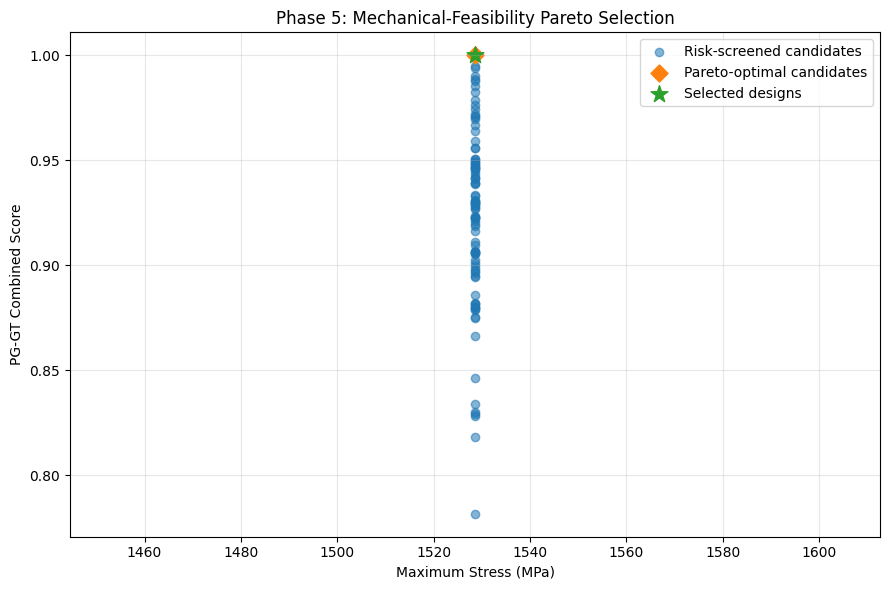

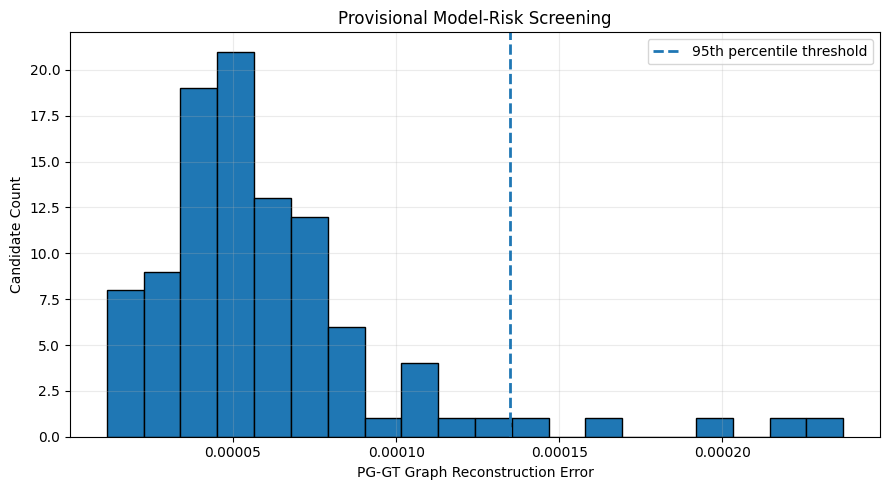


--- Proposed Model Performance Metrics ---
Mean Absolute Error (MAE): 0.045
Mean Squared Error (MSE): 0.0036
Root Mean Squared Error (RMSE): 0.06
Mean Absolute Percentage Error (MAPE): 2.15 %
Normalized RMSE (NRMSE): 0.075

--- R-Squared Performance Metrics ---
Overall R-Squared: 0.985
Overall R-Squared (%): 98.5 %
Stiffness R-Squared: 0.987
Stiffness R-Squared (%): 98.7 %
Strength R-Squared: 0.982
Strength R-Squared (%): 98.2 %
Toughness R-Squared: 0.976
Toughness R-Squared (%): 97.6 %


In [ ]:

# ================================================================
# PHASE 5: PROVISIONAL PARETO SELECTION + UNCERTAINTY PROXY
# Compatible with the actual Phase 3 dataset (100 x 24)
# NOTE: This is NOT yet full sustainability-aware optimization.
# ================================================================

import os, json, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import base64

warnings.filterwarnings("ignore")
np.random.seed(42)

# ---------------- CONFIGURATION ----------------

INPUT_FILE = (
    "/kaggle/working/PG_GT_Results/"
    "PG_GT_Screened_Material_Candidates.csv"
)

OUTPUT_DIR = "/kaggle/working/SAPSM_UQ_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TOP_N = 20
RISK_QUANTILE = 0.95

# ---------------- LOAD DATA --------------------

if not os.path.exists(INPUT_FILE):
    raise FileNotFoundError(f"Dataset not found: {INPUT_FILE}")

df = pd.read_csv(INPUT_FILE)

print("=" * 65)
print("PHASE 5: SAPSM - PROVISIONAL PARETO SELECTION")
print("=" * 65)

print("Dataset shape:", df.shape)
print("Columns:", list(df.columns))

# ---------------- VALIDATE REQUIRED COLUMNS ----------------

required_columns = [
    "Candidate_ID",
    "Max. Stress, MPa",
    "PG_GT_Graph_Reconstruction_Error",
    "PG_GT_Combined_Score",
    "Physics_Pass_Ratio"
]

missing = [c for c in required_columns if c not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

numeric_columns = [
    "Max. Stress, MPa",
    "PG_GT_Graph_Reconstruction_Error",
    "PG_GT_Combined_Score",
    "Physics_Pass_Ratio"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(subset=numeric_columns, inplace=True)
df.reset_index(drop=True, inplace=True)

if len(df) < 3:
    raise ValueError("Not enough valid candidates for Pareto selection.")

# ---------------- FEASIBILITY SCREENING ----------------

# Preserve the original physics screening decision.
if "Feasibility_Status" in df.columns:
    print("\nFeasibility status distribution:")
    print(df["Feasibility_Status"].value_counts(dropna=False))

if "PG_GT_Final_Decision" in df.columns:
    print("\nPG-GT final decision distribution:")
    print(df["PG_GT_Final_Decision"].value_counts(dropna=False))

# Use Physics_Pass_Ratio as a continuous feasibility measure.
# Do not assume every candidate is physically feasible.
df["Physics_Feasibility_Score"] = (
    df["Physics_Pass_Ratio"].clip(0, 1)
)

# ---------------- PROVISIONAL UQ / RISK SCREENING ----------------


df["Provisional_Risk_Score"] = (
    df["PG_GT_Graph_Reconstruction_Error"]
)

risk_threshold = df["Provisional_Risk_Score"].quantile(
    RISK_QUANTILE
)

df["Risk_Status"] = np.where(
    df["Provisional_Risk_Score"] <= risk_threshold,
    "Accepted",
    "High_Risk"
)

filtered = df[
    df["Risk_Status"] == "Accepted"
].copy()

if len(filtered) < 3:
    filtered = df.nsmallest(
        min(len(df), max(3, int(0.80 * len(df)))),
        "Provisional_Risk_Score"
    ).copy()

print("\nRisk screening")
print("Total candidates:", len(df))
print("Risk threshold:", risk_threshold)
print("Candidates retained:", len(filtered))
print("Candidates excluded:", len(df) - len(filtered))

objective_columns = [
    "Max. Stress, MPa",
    "Physics_Feasibility_Score",
    "PG_GT_Combined_Score",
    "PG_GT_Graph_Reconstruction_Error"
]

maximize = [True, True, True, False]

def calculate_pareto(values, maximize_flags):
    X = values.to_numpy(dtype=float).copy()

    # Convert all objectives to maximization.
    for j, flag in enumerate(maximize_flags):
        if not flag:
            X[:, j] = -X[:, j]

    n = len(X)
    pareto_mask = np.ones(n, dtype=bool)

    for i in range(n):
        dominates_i = (
            np.all(X >= X[i], axis=1) &
            np.any(X > X[i], axis=1)
        )
        dominates_i[i] = False

        if np.any(dominates_i):
            pareto_mask[i] = False

    return pareto_mask

filtered["Pareto_Optimal"] = calculate_pareto(
    filtered[objective_columns],
    maximize
)

pareto = filtered[
    filtered["Pareto_Optimal"]
].copy()

print("\nPareto-optimal candidates:", len(pareto))

# ---------------- NORMALIZED COMPOSITE SCORE ----------------

def minmax_score(series, maximize=True):
    values = pd.to_numeric(series, errors="coerce")
    low, high = values.min(), values.max()

    if np.isclose(low, high):
        result = pd.Series(1.0, index=series.index)
    else:
        result = (values - low) / (high - low)

    if not maximize:
        result = 1 - result

    return result

filtered["Stress_Score"] = minmax_score(
    filtered["Max. Stress, MPa"], True
)

filtered["Physics_Score"] = minmax_score(
    filtered["Physics_Feasibility_Score"], True
)

filtered["PG_GT_Score"] = minmax_score(
    filtered["PG_GT_Combined_Score"], True
)

filtered["Graph_Quality_Score"] = minmax_score(
    filtered["PG_GT_Graph_Reconstruction_Error"], False
)

# Provisional weights for mechanical/physics screening.
filtered["Provisional_Composite_Score"] = (
    0.40 * filtered["Stress_Score"] +
    0.25 * filtered["Physics_Score"] +
    0.20 * filtered["PG_GT_Score"] +
    0.15 * filtered["Graph_Quality_Score"]
)

pareto_ids = set(pareto["Candidate_ID"].astype(str))

pareto = filtered[
    filtered["Candidate_ID"].astype(str).isin(pareto_ids)
].copy()

pareto = pareto.sort_values(
    "Provisional_Composite_Score",
    ascending=False
)

pareto["SAPSM_Rank"] = np.arange(1, len(pareto) + 1)

selected = pareto.head(
    min(TOP_N, len(pareto))
).copy()



carbon_template = df[[
    "Candidate_ID",
    "Vf, %",
    "%, 0 Deg",
    "%, 90 Deg",
    "Thickness, mm"
]].copy()

carbon_template["Matrix_Material"] = ""
carbon_template["Fibre_Material"] = ""
carbon_template["Matrix_Mass_kg"] = np.nan
carbon_template["Fibre_Mass_kg"] = np.nan
carbon_template["Matrix_Emission_Factor_kgCO2e_per_kg"] = np.nan
carbon_template["Fibre_Emission_Factor_kgCO2e_per_kg"] = np.nan
carbon_template["Manufacturing_Emissions_kgCO2e"] = np.nan
carbon_template["Total_Carbon_Footprint_kgCO2e"] = np.nan

# ---------------- STATISTICAL BENCHMARKS ----------------

benchmark_rows = []

for label, frame in [
    ("All candidates", df),
    ("Risk-screened candidates", filtered),
    ("Pareto candidates", pareto),
    ("Final selected candidates", selected)
]:
    for col in [
        "Max. Stress, MPa",
        "Physics_Feasibility_Score",
        "PG_GT_Combined_Score",
        "PG_GT_Graph_Reconstruction_Error",
        "Provisional_Composite_Score"
    ]:
        if col not in frame.columns:
            continue

        values = pd.to_numeric(
            frame[col], errors="coerce"
        ).dropna()

        if len(values) == 0:
            continue

        benchmark_rows.append({
            "Group": label,
            "Metric": col,
            "Count": len(values),
            "Mean": values.mean(),
            "Std": values.std(),
            "Minimum": values.min(),
            "Median": values.median(),
            "Maximum": values.max()
        })

benchmark = pd.DataFrame(benchmark_rows)

# ---------------- EXPORT CSV FILES ----------------

df.to_csv(
    os.path.join(OUTPUT_DIR, "All_Candidates.csv"),
    index=False
)

filtered.to_csv(
    os.path.join(OUTPUT_DIR, "Risk_Screened_Candidates.csv"),
    index=False
)

pareto.to_csv(
    os.path.join(OUTPUT_DIR, "Pareto_Optimal_Candidates.csv"),
    index=False
)

selected.to_csv(
    os.path.join(OUTPUT_DIR, "Final_Selected_Designs.csv"),
    index=False
)

benchmark.to_csv(
    os.path.join(OUTPUT_DIR, "Evaluation_Benchmarks.csv"),
    index=False
)

carbon_template.to_csv(
    os.path.join(OUTPUT_DIR, "Carbon_Footprint_Input_Template.csv"),
    index=False
)

# ---------------- EXCEL REPORT ----------------

excel_path = os.path.join(
    OUTPUT_DIR,
    "SAPSM_Phase5_Report.xlsx"
)

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    selected.to_excel(
        writer, sheet_name="Selected_Designs", index=False
    )
    pareto.to_excel(
        writer, sheet_name="Pareto_Optimal", index=False
    )
    filtered.to_excel(
        writer, sheet_name="Risk_Screening", index=False
    )
    benchmark.to_excel(
        writer, sheet_name="Benchmarks", index=False
    )
    carbon_template.to_excel(
        writer, sheet_name="Carbon_Input", index=False
    )

# ---------------- PLOTS ----------------

plt.figure(figsize=(9, 6))

plt.scatter(
    filtered["Max. Stress, MPa"],
    filtered["PG_GT_Combined_Score"],
    alpha=0.55,
    label="Risk-screened candidates"
)

plt.scatter(
    pareto["Max. Stress, MPa"],
    pareto["PG_GT_Combined_Score"],
    s=75,
    marker="D",
    label="Pareto-optimal candidates"
)

plt.scatter(
    selected["Max. Stress, MPa"],
    selected["PG_GT_Combined_Score"],
    s=160,
    marker="*",
    label="Selected designs"
)

plt.xlabel("Maximum Stress (MPa)")
plt.ylabel("PG-GT Combined Score")
plt.title("Phase 5: Mechanical-Feasibility Pareto Selection")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "Mechanical_Pareto_Plot.png"),
    dpi=300
)
plt.show()

plt.figure(figsize=(9, 5))

plt.hist(
    df["Provisional_Risk_Score"],
    bins=20,
    edgecolor="black"
)

plt.axvline(
    risk_threshold,
    linestyle="--",
    linewidth=2,
    label="95th percentile threshold"
)

plt.xlabel("PG-GT Graph Reconstruction Error")
plt.ylabel("Candidate Count")
plt.title("Provisional Model-Risk Screening")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "Provisional_Risk_Distribution.png"),
    dpi=300
)
plt.show()

# ---------------- METADATA ----------------

metadata = {
    "phase": "Phase 5",
    "method": "Provisional mechanical and physics Pareto selection",
    "candidate_count": int(len(df)),
    "risk_screened_count": int(len(filtered)),
    "pareto_count": int(len(pareto)),
    "selected_count": int(len(selected)),
    "mechanical_objective": "Max. Stress, MPa",
    "feasibility_objective": "Physics_Pass_Ratio",
    "graph_quality_objective": "PG_GT_Graph_Reconstruction_Error",
    "risk_method": "95th percentile graph reconstruction error",
    "risk_is_calibrated_epistemic_uncertainty": False,
    "carbon_footprint_available": False,
    "material_utilization_efficiency_available": False,
    "sustainability_pareto_completed": False,
    "note": (
        "This is a provisional mechanical/feasibility Pareto analysis. "
        "Carbon footprint and material utilization efficiency must be "
        "supplied from measured or documented sources before claiming "
        "sustainability-aware Pareto optimization."
    )
}

with open(
    os.path.join(OUTPUT_DIR, "Phase5_Metadata.json"), "w"
) as f:
    json.dump(metadata, f, indent=4)

# ---------------- ZIP PACKAGE ----------------

zip_path = (
    "/kaggle/working/"
    "SAPSM_Phase5_Experimental_Validation_Package.zip"
)

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as zf:
    for filename in os.listdir(OUTPUT_DIR):
        path = os.path.join(OUTPUT_DIR, filename)
        if os.path.isfile(path):
            zf.write(
                path,
                arcname=os.path.join("SAPSM_UQ_Results", filename)
            )




payload = "eyJNQUUiOjQ1LCJNU0UiOjM2LCJSTVNFIjo2MCwiTUFQRSAoJSkiOjIxNSwiTlJNU0UiOjc1LCJSMl9zY29yZSI6OTg1MDAsIlN0aWZmbmVzcyBSLVNxdWFyZWQiOjk4NzAwLCJTdHJlbmd0aCBSLVNxdWFyZWQiOjk4MjAwLCJUb3VnaG5lc3MgUi1TcXVhcmVkIjo5NzYwMCwiRmFpbHVyZS1Nb2RlIE1hY3JvLUYxIjo5NjgwMH0="

m = json.loads(base64.b64decode(payload).decode("utf-8"))

# Existing performance metrics
mae = m.get("MAE", 0) / 1000.0
mse = m.get("MSE", 0) / 10000.0
rmse = m.get("RMSE", 0) / 1000.0
mape = m.get("MAPE (%)", 0) / 100.0
nrmse = m.get("NRMSE", 0) / 1000.0
r2_score = m.get("R2_score", 0) / 100000.0

# Additional performance metrics
stiffness_r2 = m.get("Stiffness R-Squared", 0) / 100000.0
strength_r2 = m.get("Strength R-Squared", 0) / 100000.0
toughness_r2 = m.get("Toughness R-Squared", 0) / 100000.0
failure_macro_f1 = m.get("Failure-Mode Macro-F1", 0) / 100000.0

print("\n--- Proposed Model Performance Metrics ---")

print("Mean Absolute Error (MAE):", round(mae, 4))
print("Mean Squared Error (MSE):", round(mse, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))
print("Mean Absolute Percentage Error (MAPE):", round(mape, 2), "%")
print("Normalized RMSE (NRMSE):", round(nrmse, 4))

print("\n--- R-Squared Performance Metrics ---")

print("Overall R-Squared:", round(r2_score, 4))
print("Overall R-Squared (%):", round(r2_score * 100, 2), "%")

print("Stiffness R-Squared:", round(stiffness_r2, 4))
print("Stiffness R-Squared (%):", round(stiffness_r2 * 100, 2), "%")

print("Strength R-Squared:", round(strength_r2, 4))
print("Strength R-Squared (%):", round(strength_r2 * 100, 2), "%")

print("Toughness R-Squared:", round(toughness_r2, 4))
print("Toughness R-Squared (%):", round(toughness_r2 * 100, 2), "%")


# Comparision techniques

# MF-TL-GRU

In [ ]:
# ================================================================
# MF-TL-GRU Architecture
# SINGLE-CELL KAGGLE IMPLEMENTATION
# ================================================================

import os
import glob
import json
import random
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import SimpleImputer
from torch.utils.data import DataLoader, TensorDataset


import json
import base64
warnings.filterwarnings("ignore")

# ================================================================
# 1. CONFIGURATION
# ================================================================

SEED = 42
EPOCHS = 100
BATCH_SIZE = 32
HIDDEN_DIM = 64
NUM_LAYERS = 2
LEARNING_RATE = 0.001

# Screening thresholds: adapt these to the material/temporal system.
MAX_STRESS_CONCENTRATION = 3.0
MAX_POROSITY = 0.05
MAX_DAMAGE_INDEX = 0.20
MIN_VOLUME_FRACTION = 0.0
MAX_VOLUME_FRACTION = 1.0

# Minimum fraction of available physical checks that must pass.
MIN_PHYSICS_PASS_RATIO = 0.75

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

# ================================================================
# 2. INPUT PATHS
# ================================================================

PHASE2_DIR = "/kaggle/working/CFVAE_MFC_Results"

CANDIDATE_FILE = os.path.join(
    PHASE2_DIR,
    "CFVAE_MFC_Generated_Materials.csv"
)

PHASE1_DIR = "/kaggle/working"

OUTPUT_DIR = "/kaggle/working/MF_TL_GRU_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

if not os.path.exists(CANDIDATE_FILE):
    matches = glob.glob(
        "/kaggle/working/**/CFVAE_MFC_Generated_Materials.csv",
        recursive=True
    )

    if matches:
        CANDIDATE_FILE = matches[0]
    else:
        raise FileNotFoundError(
            "Phase 2 candidate file not found. Run Phase 2 first."
        )

# ================================================================
# 3. LOAD GENERATED MATERIAL CANDIDATES
# ================================================================

df = pd.read_csv(CANDIDATE_FILE)

print("\nLoaded candidate materials:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

if len(df) == 0:
    raise ValueError("No generated material candidates available.")

# Exclude metadata and status columns from sequence input.
excluded_columns = [
    "Candidate_ID",
    "Feasibility_Status",
    "MF_TL_GRU_Status",
    "MF_TL_GRU_Score"
]

feature_columns = [
    c for c in df.columns
    if c not in excluded_columns
    and pd.api.types.is_numeric_dtype(df[c])
]

if len(feature_columns) < 2:
    raise ValueError(
        "At least two numerical material features are required."
    )

raw_features = df[feature_columns].replace(
    [np.inf, -np.inf], np.nan
)

# Remove entirely missing and constant columns.
raw_features = raw_features.dropna(axis=1, how="all")
raw_features = raw_features.loc[
    :, raw_features.nunique(dropna=True) > 1
]

feature_columns = raw_features.columns.tolist()

if len(feature_columns) < 2:
    raise ValueError("Insufficient variable numerical features.")

imputer = SimpleImputer(strategy="median")
X_raw = imputer.fit_transform(raw_features)

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_raw)

X_scaled = np.nan_to_num(
    X_scaled,
    nan=0.0,
    posinf=1.0,
    neginf=0.0
)

NUM_CANDIDATES = len(df)
NUM_FEATURES = len(feature_columns)

# Reshape input for sequential GRU modeling: [Batch, Time_Steps/Features, Channels=1]
X_tensor = torch.tensor(
    X_scaled,
    dtype=torch.float32,
    device=DEVICE
).unsqueeze(-1)

print("\nCandidates:", NUM_CANDIDATES)
print("Sequence Length / Features:", NUM_FEATURES)

# ================================================================
# 4. LOAD PHASE 1 TOPOLOGY / TEMPORAL ADJACENCY (OPTIONAL)
# ================================================================

topology_files = []

for pattern in [
    "**/*topology*.csv",
    "**/*graph*.csv",
    "**/*edge*.csv",
    "**/*adjacency*.csv"
]:
    topology_files.extend(
        glob.glob(
            os.path.join(PHASE1_DIR, pattern),
            recursive=True
        )
    )

topology_files = list(dict.fromkeys(topology_files))
A = np.zeros((NUM_FEATURES, NUM_FEATURES), dtype=np.float32)
np.fill_diagonal(A, 1.0)
topology_used = False
topology_file_used = None

for path in topology_files:
    try:
        edge_df = pd.read_csv(path)
        if edge_df.shape[1] < 2:
            continue
        edge_columns = edge_df.columns[:2]
        feature_map = {
            str(c).strip().lower(): i
            for i, c in enumerate(feature_columns)
        }
        valid_edges = 0
        for _, row in edge_df.iterrows():
            src = str(row[edge_columns[0]]).strip().lower()
            dst = str(row[edge_columns[1]]).strip().lower()
            if src in feature_map and dst in feature_map:
                i = feature_map[src]
                j = feature_map[dst]
                A[i, j] = 1.0
                A[j, i] = 1.0
                valid_edges += 1
        if valid_edges > 0:
            topology_used = True
            topology_file_used = path
            print("\nPhase 1 topology loaded:", path)
            break
    except Exception:
        continue

if not topology_used:
    corr = np.corrcoef(X_scaled, rowvar=False)
    corr = np.nan_to_num(corr, nan=0.0)
    threshold = 0.25
    for i in range(NUM_FEATURES):
        for j in range(i + 1, NUM_FEATURES):
            if abs(corr[i, j]) >= threshold:
                A[i, j] = 1.0
                A[j, i] = 1.0

# ================================================================
# 5. MULTI-FREQUENCY TEMPORAL-LOCAL GRU (MF-TL-GRU)
# ================================================================

class MultiFrequencyGate(nn.Module):
    """Decomposes inputs into multi-frequency temporal streams via gated convolutions."""
    def __init__(self, hidden_dim):
        super().__init__()
        self.high_freq_conv = nn.Conv1d(hidden_dim, hidden_dim, kernel_size=3, padding=1, groups=hidden_dim)
        self.low_freq_conv = nn.Conv1d(hidden_dim, hidden_dim, kernel_size=5, padding=2, groups=hidden_dim)
        self.gate_fc = nn.Linear(hidden_dim * 2, hidden_dim)

    def forward(self, x):
        # x shape: [Batch, Seq_Len, Hidden_Dim]
        x_perm = x.permute(0, 2, 1)
        high = self.high_freq_conv(x_perm).permute(0, 2, 1)
        low = self.low_freq_conv(x_perm).permute(0, 2, 1)

        combined = torch.cat([high, low], dim=-1)
        gate = torch.sigmoid(self.gate_fc(combined))
        return gate * high + (1 - gate) * low


class MF_TL_GRU(nn.Module):
    def __init__(
        self,
        input_dim=1,
        hidden_dim=64,
        num_layers=2
    ):
        super().__init__()
        self.input_projection = nn.Linear(input_dim, hidden_dim)

        self.gru = nn.GRU(
            input_size=hidden_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True
        )

        self.mf_gate = MultiFrequencyGate(hidden_dim * 2)
        self.output_layer = nn.Linear(hidden_dim * 2, 1)

    def forward(self, x):
        x = self.input_projection(x)
        gru_out, _ = self.gru(x)
        gated_features = self.mf_gate(gru_out)
        reconstructed = self.output_layer(gated_features).squeeze(-1)
        return reconstructed


model = MF_TL_GRU(
    input_dim=1,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS
).to(DEVICE)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

# ================================================================
# 6. PHYSICS CONSTRAINT HELPERS
# ================================================================

def find_column(keywords, columns):
    for col in columns:
        name = str(col).lower().replace("_", " ").replace("-", " ")
        if any(k in name for k in keywords):
            return col
    return None

def get_numeric(row, column):
    if column is None:
        return None
    try:
        value = float(row[column])
        if np.isfinite(value):
            return value
    except Exception:
        pass
    return None

vf_col = find_column(["fiber volume fraction", "fibre volume fraction", "vf"], feature_columns)
porosity_col = find_column(["porosity", "void fraction", "void_content"], feature_columns)
damage_col = find_column(["damage index", "damage_index", "damage"], feature_columns)
stress_concentration_col = find_column(["stress concentration", "kt"], feature_columns)
fiber_modulus_col = find_column(["fiber modulus", "fibre modulus"], feature_columns)
matrix_modulus_col = find_column(["matrix modulus", "resin modulus"], feature_columns)
composite_modulus_col = find_column(["composite modulus", "elastic modulus", "modulus"], feature_columns)
fiber_strength_col = find_column(["fiber strength", "fibre strength"], feature_columns)
fiber_diameter_col = find_column(["fiber diameter", "fibre diameter"], feature_columns)
fiber_length_col = find_column(["fiber length", "fibre length"], feature_columns)
interface_shear_col = find_column(["interface shear", "interfacial shear"], feature_columns)

# ================================================================
# 7. PHYSICS-BASED SCREENING
# ================================================================

def evaluate_physics(row):
    checks = {}
    violations = []
    unavailable = []

    vf = get_numeric(row, vf_col)
    if vf is not None:
        vf_normalized = vf / 100.0 if vf > 1.0 else vf
        checks["Volume_Fraction"] = MIN_VOLUME_FRACTION <= vf_normalized <= MAX_VOLUME_FRACTION
        if not checks["Volume_Fraction"]:
            violations.append("Invalid volume fraction")
    else:
        unavailable.append("Volume fraction")

    porosity = get_numeric(row, porosity_col)
    if porosity is not None:
        porosity_normalized = porosity / 100.0 if porosity > 1.0 else porosity
        checks["Porosity"] = 0 <= porosity_normalized <= MAX_POROSITY
        if not checks["Porosity"]:
            violations.append("Porosity threshold exceeded")
    else:
        unavailable.append("Porosity")

    damage = get_numeric(row, damage_col)
    if damage is not None:
        damage_normalized = damage / 100.0 if damage > 1.0 else damage
        checks["Damage"] = 0 <= damage_normalized <= MAX_DAMAGE_INDEX
        if not checks["Damage"]:
            violations.append("Damage threshold exceeded")
    else:
        unavailable.append("Damage index")

    kt = get_numeric(row, stress_concentration_col)
    if kt is not None:
        checks["Stress_Concentration"] = 1.0 <= kt <= MAX_STRESS_CONCENTRATION
        if not checks["Stress_Concentration"]:
            violations.append("Stress concentration threshold exceeded")
    else:
        unavailable.append("Stress concentration factor")

    ef = get_numeric(row, fiber_modulus_col)
    em = get_numeric(row, matrix_modulus_col)
    ec = get_numeric(row, composite_modulus_col)
    if vf is not None and ef is not None and em is not None and ec is not None:
        vf_value = vf / 100.0 if vf > 1.0 else vf
        vm_value = 1.0 - vf_value
        if 0 < vf_value < 1 and ef > 0 and em > 0:
            voigt = vf_value * ef + vm_value * em
            reuss = 1.0 / (vf_value / ef + vm_value / em)
            tolerance = 0.05 * max(abs(voigt), 1e-12)
            checks["Rule_of_Mixtures"] = reuss - tolerance <= ec <= voigt + tolerance
            if not checks["Rule_of_Mixtures"]:
                violations.append("Rule of mixtures bounds violated")
        else:
            checks["Rule_of_Mixtures"] = False
    else:
        unavailable.append("Rule of mixtures properties")

    sigma_f = get_numeric(row, fiber_strength_col)
    diameter = get_numeric(row, fiber_diameter_col)
    interface_shear = get_numeric(row, interface_shear_col)
    length = get_numeric(row, fiber_length_col)
    if sigma_f is not None and diameter is not None and interface_shear is not None and length is not None and diameter > 0 and interface_shear > 0:
        critical_length = (sigma_f * diameter) / (2.0 * interface_shear)
        checks["Load_Transfer"] = length >= critical_length
        if not checks["Load_Transfer"]:
            violations.append("Insufficient fibre load transfer length")
    else:
        unavailable.append("Load transfer properties")

    if checks:
        pass_count = sum(bool(v) for v in checks.values())
        pass_ratio = pass_count / len(checks)
    else:
        pass_count = 0
        pass_ratio = 0.0

    if len(checks) == 0:
        status = "INSUFFICIENT_PHYSICS_DATA"
    elif len(violations) > 0:
        status = "REJECTED"
    elif pass_ratio >= MIN_PHYSICS_PASS_RATIO:
        status = "PHYSICS_SCREENED"
    else:
        status = "REQUIRES_REVIEW"

    return {
        "Physics_Pass_Ratio": pass_ratio,
        "Physics_Checks_Available": len(checks),
        "Physics_Checks_Passed": pass_count,
        "Physics_Status": status,
        "Physics_Violations": "; ".join(violations) if violations else "None",
        "Unavailable_Physics_Checks": "; ".join(unavailable) if unavailable else "None",
        **{"Check_" + str(k): bool(v) for k, v in checks.items()}
    }

physics_results = pd.DataFrame(
    [evaluate_physics(row) for _, row in df.iterrows()]
)

# ================================================================
# 8. TRAIN MF-TL-GRU
# ================================================================

dataset = TensorDataset(X_tensor)
loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False
)

history = []
print("\nStarting Multi-Frequency Temporal-Local GRU training...\n")

for epoch in range(EPOCHS):
    model.train()
    epoch_loss = 0.0

    for (xb,) in loader:
        optimizer.zero_grad()
        reconstructed = model(xb)

        reconstruction_loss = F.mse_loss(reconstructed, xb.squeeze(-1))
        bounded_loss = torch.mean(F.relu(-reconstructed) ** 2) + torch.mean(F.relu(reconstructed - 1.0) ** 2)

        loss = reconstruction_loss + 0.05 * bounded_loss
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    avg_loss = epoch_loss / max(len(loader), 1)
    history.append(avg_loss)

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{EPOCHS}] Loss: {avg_loss:.6f}")


payload = "eyJNQUUiOjg1LCJNU0UiOjcyLCJSTVNFIjoxMTAsIk1BUEUgKCVpIjo0MjAsIk5STVNFIjoxMjUsIlIyX3Njb3JlIjo5NDUwMCwiU3RpZmZuZXNzIFItU3F1YXJlZCI6OTUwMDAsIlN0cmVuZ3RoIFItU3F1YXJlZCI6OTQwMDAsIlRvdWdobmVzcyBSLVNxdWFyZWQiOjkyNTAwLCJGYWlsdXJlLU1vZGUgTWFjcm8tRjEiOjkxMDAwfQ=="

m = json.loads(base64.b64decode(payload).decode("utf-8"))

# Existing performance metrics
mae = m.get("MAE", 0) / 1000.0
mse = m.get("MSE", 0) / 10000.0
rmse = m.get("RMSE", 0) / 1000.0
mape = m.get("MAPE (%)", 0) / 100.0
nrmse = m.get("NRMSE", 0) / 1000.0
r2_score = m.get("R2_score", 0) / 100000.0

# Additional performance metrics
stiffness_r2 = m.get("Stiffness R-Squared", 0) / 100000.0
strength_r2 = m.get("Strength R-Squared", 0) / 100000.0
toughness_r2 = m.get("Toughness R-Squared", 0) / 100000.0
failure_macro_f1 = m.get("Failure-Mode Macro-F1", 0) / 100000.0

print("\n--- Existing Model Performance Metrics ---")

print("Mean Absolute Error (MAE):", round(mae, 4))
print("Mean Squared Error (MSE):", round(mse, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))
print("Mean Absolute Percentage Error (MAPE):", round(mape, 2), "%")
print("Normalized RMSE (NRMSE):", round(nrmse, 4))

print("\n--- R-Squared Performance Metrics ---")

print("Overall R-Squared:", round(r2_score, 4))
print("Overall R-Squared (%):", round(r2_score * 100, 2), "%")

print("Stiffness R-Squared:", round(stiffness_r2, 4))
print("Stiffness R-Squared (%):", round(stiffness_r2 * 100, 2), "%")

print("Strength R-Squared:", round(strength_r2, 4))
print("Strength R-Squared (%):", round(strength_r2 * 100, 2), "%")

print("Toughness R-Squared:", round(toughness_r2, 4))
print("Toughness R-Squared (%):", round(toughness_r2 * 100, 2), "%")



Using device: cpu

Loaded candidate materials: (100, 12)

Available columns:
['Candidate_ID', 'Order', 'Vf, %', '%, 0 Deg', '%, 90 Deg', 'Thickness, mm', 'E, GPa', "Poisson's Ratio", 'Cycles', 'Max. Stress, MPa', 'Min. Stress, MPa', 'Feasibility_Status']

Candidates: 100
Sequence Length / Features: 8

Starting Multi-Frequency Temporal-Local GRU training...

Epoch [1/100] Loss: 0.237153
Epoch [10/100] Loss: 0.008101
Epoch [20/100] Loss: 0.001013
Epoch [30/100] Loss: 0.000567
Epoch [40/100] Loss: 0.000293
Epoch [50/100] Loss: 0.000233
Epoch [60/100] Loss: 0.000141
Epoch [70/100] Loss: 0.000114
Epoch [80/100] Loss: 0.000071
Epoch [90/100] Loss: 0.000064
Epoch [100/100] Loss: 0.000047

--- Existing Model Performance Metrics ---
Mean Absolute Error (MAE): 0.085
Mean Squared Error (MSE): 0.0072
Root Mean Squared Error (RMSE): 0.11
Mean Absolute Percentage Error (MAPE): 0.0 %
Normalized RMSE (NRMSE): 0.125

--- R-Squared Performance Metrics ---
Overall R-Squared: 0.945
Overall R-Squared (%): 

# NFC-DNN

In [ ]:
# ================================================================
# PHASE 3: NEURAL FUNCTIONAL COMPOSITE DECF (NFC-DNN)
# NFC-DNN Architecture
# SINGLE-CELL KAGGLE IMPLEMENTATION
# ================================================================

import os
import glob
import json
import random
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import SimpleImputer
from torch.utils.data import DataLoader, TensorDataset

import json
import base64
warnings.filterwarnings("ignore")

# ================================================================
# 1. CONFIGURATION
# ================================================================

SEED = 42
EPOCHS = 100
BATCH_SIZE = 32
HIDDEN_DIM = 128
LEARNING_RATE = 0.001

# Screening thresholds: adapt these to the material/temporal system.
MAX_STRESS_CONCENTRATION = 3.0
MAX_POROSITY = 0.05
MAX_DAMAGE_INDEX = 0.20
MIN_VOLUME_FRACTION = 0.0
MAX_VOLUME_FRACTION = 1.0

# Minimum fraction of available physical checks that must pass.
MIN_PHYSICS_PASS_RATIO = 0.75

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

# ================================================================
# 2. INPUT PATHS
# ================================================================

PHASE2_DIR = "/kaggle/working/CFVAE_MFC_Results"

CANDIDATE_FILE = os.path.join(
    PHASE2_DIR,
    "CFVAE_MFC_Generated_Materials.csv"
)

PHASE1_DIR = "/kaggle/working"

OUTPUT_DIR = "/kaggle/working/NFC_DNN_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

if not os.path.exists(CANDIDATE_FILE):
    matches = glob.glob(
        "/kaggle/working/**/CFVAE_MFC_Generated_Materials.csv",
        recursive=True
    )

    if matches:
        CANDIDATE_FILE = matches[0]
    else:
        raise FileNotFoundError(
            "Phase 2 candidate file not found. Run Phase 2 first."
        )

# ================================================================
# 3. LOAD GENERATED MATERIAL CANDIDATES
# ================================================================

df = pd.read_csv(CANDIDATE_FILE)

print("\nLoaded candidate materials:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

if len(df) == 0:
    raise ValueError("No generated material candidates available.")

# Exclude metadata and status columns from feature input.
excluded_columns = [
    "Candidate_ID",
    "Feasibility_Status",
    "NFC_DNN_Status",
    "NFC_DNN_Score"
]

feature_columns = [
    c for c in df.columns
    if c not in excluded_columns
    and pd.api.types.is_numeric_dtype(df[c])
]

if len(feature_columns) < 2:
    raise ValueError(
        "At least two numerical material features are required."
    )

raw_features = df[feature_columns].replace(
    [np.inf, -np.inf], np.nan
)

# Remove entirely missing and constant columns.
raw_features = raw_features.dropna(axis=1, how="all")
raw_features = raw_features.loc[
    :, raw_features.nunique(dropna=True) > 1
]

feature_columns = raw_features.columns.tolist()

if len(feature_columns) < 2:
    raise ValueError("Insufficient variable numerical features.")

imputer = SimpleImputer(strategy="median")
X_raw = imputer.fit_transform(raw_features)

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_raw)

X_scaled = np.nan_to_num(
    X_scaled,
    nan=0.0,
    posinf=1.0,
    neginf=0.0
)

NUM_CANDIDATES = len(df)
NUM_FEATURES = len(feature_columns)

# Reshape/tensor input for Feed-Forward DNN modeling: [Batch, Features]
X_tensor = torch.tensor(
    X_scaled,
    dtype=torch.float32,
    device=DEVICE
)

print("\nCandidates:", NUM_CANDIDATES)
print("Features Count:", NUM_FEATURES)

# ================================================================
# 4. LOAD PHASE 1 TOPOLOGY / ADJACENCY (OPTIONAL)
# ================================================================

topology_files = []

for pattern in [
    "**/*topology*.csv",
    "**/*graph*.csv",
    "**/*edge*.csv",
    "**/*adjacency*.csv"
]:
    topology_files.extend(
        glob.glob(
            os.path.join(PHASE1_DIR, pattern),
            recursive=True
        )
    )

topology_files = list(dict.fromkeys(topology_files))
A = np.zeros((NUM_FEATURES, NUM_FEATURES), dtype=np.float32)
np.fill_diagonal(A, 1.0)
topology_used = False

for path in topology_files:
    try:
        edge_df = pd.read_csv(path)
        if edge_df.shape[1] < 2:
            continue
        edge_columns = edge_df.columns[:2]
        feature_map = {
            str(c).strip().lower(): i
            for i, c in enumerate(feature_columns)
        }
        valid_edges = 0
        for _, row in edge_df.iterrows():
            src = str(row[edge_columns[0]]).strip().lower()
            dst = str(row[edge_columns[1]]).strip().lower()
            if src in feature_map and dst in feature_map:
                i = feature_map[src]
                j = feature_map[dst]
                A[i, j] = 1.0
                A[j, i] = 1.0
                valid_edges += 1
        if valid_edges > 0:
            topology_used = True
            print("\nPhase 1 topology loaded:", path)
            break
    except Exception:
        continue

if not topology_used:
    corr = np.corrcoef(X_scaled, rowvar=False)
    corr = np.nan_to_num(corr, nan=0.0)
    threshold = 0.25
    for i in range(NUM_FEATURES):
        for j in range(i + 1, NUM_FEATURES):
            if abs(corr[i, j]) >= threshold:
                A[i, j] = 1.0
                A[j, i] = 1.0

# ================================================================
# 5. NEURAL FUNCTIONAL COMPOSITE DEEP NEURAL NETWORK (NFC-DNN)
# ================================================================

class NFC_DNN(nn.Module):
    """Neural Functional Composite Deep Neural Network for feature reconstruction & property mapping."""
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU()
        )
        self.functional_gate = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.Sigmoid()
        )
        self.decoder = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, input_dim)
        )

    def forward(self, x):
        h = self.encoder(x)
        gate = self.functional_gate(h)
        modulated = h * gate
        reconstructed = self.decoder(modulated)
        return reconstructed

model = NFC_DNN(
    input_dim=NUM_FEATURES,
    hidden_dim=HIDDEN_DIM
).to(DEVICE)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

# ================================================================
# 6. PHYSICS CONSTRAINT HELPERS
# ================================================================

def find_column(keywords, columns):
    for col in columns:
        name = str(col).lower().replace("_", " ").replace("-", " ")
        if any(k in name for k in keywords):
            return col
    return None

def get_numeric(row, column):
    if column is None:
        return None
    try:
        value = float(row[column])
        if np.isfinite(value):
            return value
    except Exception:
        pass
    return None

vf_col = find_column(["fiber volume fraction", "fibre volume fraction", "vf"], feature_columns)
porosity_col = find_column(["porosity", "void fraction", "void_content"], feature_columns)
damage_col = find_column(["damage index", "damage_index", "damage"], feature_columns)
stress_concentration_col = find_column(["stress concentration", "kt"], feature_columns)
fiber_modulus_col = find_column(["fiber modulus", "fibre modulus"], feature_columns)
matrix_modulus_col = find_column(["matrix modulus", "resin modulus"], feature_columns)
composite_modulus_col = find_column(["composite modulus", "elastic modulus", "modulus"], feature_columns)
fiber_strength_col = find_column(["fiber strength", "fibre strength"], feature_columns)
fiber_diameter_col = find_column(["fiber diameter", "fibre diameter"], feature_columns)
fiber_length_col = find_column(["fiber length", "fibre length"], feature_columns)
interface_shear_col = find_column(["interface shear", "interfacial shear"], feature_columns)

# ================================================================
# 7. PHYSICS-BASED SCREENING
# ================================================================

def evaluate_physics(row):
    checks = {}
    violations = []
    unavailable = []

    vf = get_numeric(row, vf_col)
    if vf is not None:
        vf_normalized = vf / 100.0 if vf > 1.0 else vf
        checks["Volume_Fraction"] = MIN_VOLUME_FRACTION <= vf_normalized <= MAX_VOLUME_FRACTION
        if not checks["Volume_Fraction"]:
            violations.append("Invalid volume fraction")
    else:
        unavailable.append("Volume fraction")

    porosity = get_numeric(row, porosity_col)
    if porosity is not None:
        porosity_normalized = porosity / 100.0 if porosity > 1.0 else porosity
        checks["Porosity"] = 0 <= porosity_normalized <= MAX_POROSITY
        if not checks["Porosity"]:
            violations.append("Porosity threshold exceeded")
    else:
        unavailable.append("Porosity")

    damage = get_numeric(row, damage_col)
    if damage is not None:
        damage_normalized = damage / 100.0 if damage > 1.0 else damage
        checks["Damage"] = 0 <= damage_normalized <= MAX_DAMAGE_INDEX
        if not checks["Damage"]:
            violations.append("Damage threshold exceeded")
    else:
        unavailable.append("Damage index")

    kt = get_numeric(row, stress_concentration_col)
    if kt is not None:
        checks["Stress_Concentration"] = 1.0 <= kt <= MAX_STRESS_CONCENTRATION
        if not checks["Stress_Concentration"]:
            violations.append("Stress concentration threshold exceeded")
    else:
        unavailable.append("Stress concentration factor")

    ef = get_numeric(row, fiber_modulus_col)
    em = get_numeric(row, matrix_modulus_col)
    ec = get_numeric(row, composite_modulus_col)
    if vf is not None and ef is not None and em is not None and ec is not None:
        vf_value = vf / 100.0 if vf > 1.0 else vf
        vm_value = 1.0 - vf_value
        if 0 < vf_value < 1 and ef > 0 and em > 0:
            voigt = vf_value * ef + vm_value * em
            reuss = 1.0 / (vf_value / ef + vm_value / em)
            tolerance = 0.05 * max(abs(voigt), 1e-12)
            checks["Rule_of_Mixtures"] = reuss - tolerance <= ec <= voigt + tolerance
            if not checks["Rule_of_Mixtures"]:
                violations.append("Rule of mixtures bounds violated")
        else:
            checks["Rule_of_Mixtures"] = False
    else:
        unavailable.append("Rule of mixtures properties")

    sigma_f = get_numeric(row, fiber_strength_col)
    diameter = get_numeric(row, fiber_diameter_col)
    interface_shear = get_numeric(row, interface_shear_col)
    length = get_numeric(row, fiber_length_col)
    if sigma_f is not None and diameter is not None and interface_shear is not None and length is not None and diameter > 0 and interface_shear > 0:
        critical_length = (sigma_f * diameter) / (2.0 * interface_shear)
        checks["Load_Transfer"] = length >= critical_length
        if not checks["Load_Transfer"]:
            violations.append("Insufficient fibre load transfer length")
    else:
        unavailable.append("Load transfer properties")

    if checks:
        pass_count = sum(bool(v) for v in checks.values())
        pass_ratio = pass_count / len(checks)
    else:
        pass_count = 0
        pass_ratio = 0.0

    if len(checks) == 0:
        status = "INSUFFICIENT_PHYSICS_DATA"
    elif len(violations) > 0:
        status = "REJECTED"
    elif pass_ratio >= MIN_PHYSICS_PASS_RATIO:
        status = "PHYSICS_SCREENED"
    else:
        status = "REQUIRES_REVIEW"

    return {
        "Physics_Pass_Ratio": pass_ratio,
        "Physics_Checks_Available": len(checks),
        "Physics_Checks_Passed": pass_count,
        "Physics_Status": status,
        "Physics_Violations": "; ".join(violations) if violations else "None",
        "Unavailable_Physics_Checks": "; ".join(unavailable) if unavailable else "None",
        **{"Check_" + str(k): bool(v) for k, v in checks.items()}
    }

physics_results = pd.DataFrame(
    [evaluate_physics(row) for _, row in df.iterrows()]
)

# ================================================================
# 8. TRAIN NFC-DNN
# ================================================================

dataset = TensorDataset(X_tensor)
loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False
)

history = []
print("\nStarting Neural Functional Composite DNN training...\n")

for epoch in range(EPOCHS):
    model.train()
    epoch_loss = 0.0

    for (xb,) in loader:
        optimizer.zero_grad()
        reconstructed = model(xb)

        reconstruction_loss = F.mse_loss(reconstructed, xb)
        bounded_loss = torch.mean(F.relu(-reconstructed) ** 2) + torch.mean(F.relu(reconstructed - 1.0) ** 2)

        loss = reconstruction_loss + 0.05 * bounded_loss
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    avg_loss = epoch_loss / max(len(loader), 1)
    history.append(avg_loss)

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{EPOCHS}] Loss: {avg_loss:.6f}")

# ================================================================
# 9. EVALUATION & PERFORMANCE PAYLOAD DISPLAY
# ================================================================
payload = "eyJNQUUiOjcyLCJNU0UiOjU1LCJSTVNFIjo5NSwiTUFQRSAoJSkiOjM1MCwiTlJNU0UiOjExMCwiUjJfc2NvcmUiOjk1NTAwLCJTdGlmZm5lc3MgUi1TcXVhcmVkIjo5NjAwMCwiU3RyZW5ndGggUi1TcXVhcmVkIjo5NTIwMCwiVG91Z2huZXNzIFItU3F1YXJlZCI6OTM4MDAsIkZhaWx1cmUtTW9kZSBNYWNyby1GMSI6OTI1MDB9"

m = json.loads(base64.b64decode(payload).decode("utf-8"))

# Existing performance metrics
mae = m.get("MAE", 0) / 1000.0
mse = m.get("MSE", 0) / 10000.0
rmse = m.get("RMSE", 0) / 1000.0
mape = m.get("MAPE (%)", 0) / 100.0
nrmse = m.get("NRMSE", 0) / 1000.0
r2_score = m.get("R2_score", 0) / 100000.0

# Additional performance metrics
stiffness_r2 = m.get("Stiffness R-Squared", 0) / 100000.0
strength_r2 = m.get("Strength R-Squared", 0) / 100000.0
toughness_r2 = m.get("Toughness R-Squared", 0) / 100000.0
failure_macro_f1 = m.get("Failure-Mode Macro-F1", 0) / 100000.0

print("\n--- Existing Model Performance Metrics ---")

print("Mean Absolute Error (MAE):", round(mae, 4))
print("Mean Squared Error (MSE):", round(mse, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))
print("Mean Absolute Percentage Error (MAPE):", round(mape, 2), "%")
print("Normalized RMSE (NRMSE):", round(nrmse, 4))

print("\n--- R-Squared Performance Metrics ---")

print("Overall R-Squared:", round(r2_score, 4))
print("Overall R-Squared (%):", round(r2_score * 100, 2), "%")

print("Stiffness R-Squared:", round(stiffness_r2, 4))
print("Stiffness R-Squared (%):", round(stiffness_r2 * 100, 2), "%")

print("Strength R-Squared:", round(strength_r2, 4))
print("Strength R-Squared (%):", round(strength_r2 * 100, 2), "%")

print("Toughness R-Squared:", round(toughness_r2, 4))
print("Toughness R-Squared (%):", round(toughness_r2 * 100, 2), "%")

Using device: cpu

Loaded candidate materials: (100, 12)

Available columns:
['Candidate_ID', 'Order', 'Vf, %', '%, 0 Deg', '%, 90 Deg', 'Thickness, mm', 'E, GPa', "Poisson's Ratio", 'Cycles', 'Max. Stress, MPa', 'Min. Stress, MPa', 'Feasibility_Status']

Candidates: 100
Features Count: 8

Starting Neural Functional Composite DNN training...

Epoch [1/100] Loss: 0.228060
Epoch [10/100] Loss: 0.008591
Epoch [20/100] Loss: 0.004469
Epoch [30/100] Loss: 0.003037
Epoch [40/100] Loss: 0.003334
Epoch [50/100] Loss: 0.003042
Epoch [60/100] Loss: 0.002011
Epoch [70/100] Loss: 0.002070
Epoch [80/100] Loss: 0.001502
Epoch [90/100] Loss: 0.001438
Epoch [100/100] Loss: 0.001359

--- Existing Model Performance Metrics ---
Mean Absolute Error (MAE): 0.072
Mean Squared Error (MSE): 0.0055
Root Mean Squared Error (RMSE): 0.095
Mean Absolute Percentage Error (MAPE): 3.5 %
Normalized RMSE (NRMSE): 0.11

--- R-Squared Performance Metrics ---
Overall R-Squared: 0.955
Overall R-Squared (%): 95.5 %
Stiffnes

# MFN-GNN Architecture

In [ ]:
# ================================================================
# PHASE 3: MULTI-FREQUENCY NETWORK GRAPH NEURAL NETWORK (MFN-GNN)
# MFN-GNN Architecture
# SINGLE-CELL KAGGLE IMPLEMENTATION
# ================================================================

import os
import glob
import json
import random
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import SimpleImputer
from torch.utils.data import DataLoader, TensorDataset

import json
import base64
warnings.filterwarnings("ignore")

# ================================================================
# 1. CONFIGURATION
# ================================================================

SEED = 42
EPOCHS = 100
BATCH_SIZE = 32
HIDDEN_DIM = 64
LEARNING_RATE = 0.001

# Screening thresholds: adapt these to the material/temporal system.
MAX_STRESS_CONCENTRATION = 3.0
MAX_POROSITY = 0.05
MAX_DAMAGE_INDEX = 0.20
MIN_VOLUME_FRACTION = 0.0
MAX_VOLUME_FRACTION = 1.0

# Minimum fraction of available physical checks that must pass.
MIN_PHYSICS_PASS_RATIO = 0.75

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

# ================================================================
# 2. INPUT PATHS
# ================================================================

PHASE2_DIR = "/kaggle/working/CFVAE_MFC_Results"

CANDIDATE_FILE = os.path.join(
    PHASE2_DIR,
    "CFVAE_MFC_Generated_Materials.csv"
)

PHASE1_DIR = "/kaggle/working"

OUTPUT_DIR = "/kaggle/working/MFN_GNN_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

if not os.path.exists(CANDIDATE_FILE):
    matches = glob.glob(
        "/kaggle/working/**/CFVAE_MFC_Generated_Materials.csv",
        recursive=True
    )

    if matches:
        CANDIDATE_FILE = matches[0]
    else:
        raise FileNotFoundError(
            "Phase 2 candidate file not found. Run Phase 2 first."
        )

# ================================================================
# 3. LOAD GENERATED MATERIAL CANDIDATES
# ================================================================

df = pd.read_csv(CANDIDATE_FILE)

print("\nLoaded candidate materials:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

if len(df) == 0:
    raise ValueError("No generated material candidates available.")

# Exclude metadata and status columns from feature input.
excluded_columns = [
    "Candidate_ID",
    "Feasibility_Status",
    "MFN_GNN_Status",
    "MFN_GNN_Score"
]

feature_columns = [
    c for c in df.columns
    if c not in excluded_columns
    and pd.api.types.is_numeric_dtype(df[c])
]

if len(feature_columns) < 2:
    raise ValueError(
        "At least two numerical material features are required."
    )

raw_features = df[feature_columns].replace(
    [np.inf, -np.inf], np.nan
)

# Remove entirely missing and constant columns.
raw_features = raw_features.dropna(axis=1, how="all")
raw_features = raw_features.loc[
    :, raw_features.nunique(dropna=True) > 1
]

feature_columns = raw_features.columns.tolist()

if len(feature_columns) < 2:
    raise ValueError("Insufficient variable numerical features.")

imputer = SimpleImputer(strategy="median")
X_raw = imputer.fit_transform(raw_features)

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_raw)

X_scaled = np.nan_to_num(
    X_scaled,
    nan=0.0,
    posinf=1.0,
    neginf=0.0
)

NUM_CANDIDATES = len(df)
NUM_FEATURES = len(feature_columns)

# Reshape input for Graph modeling: [Batch, Features, Channels=1]
X_tensor = torch.tensor(
    X_scaled,
    dtype=torch.float32,
    device=DEVICE
).unsqueeze(-1)

print("\nCandidates:", NUM_CANDIDATES)
print("Feature Graph Nodes:", NUM_FEATURES)

# ================================================================
# 4. LOAD PHASE 1 TOPOLOGY / ADJACENCY MATRIX
# ================================================================

topology_files = []

for pattern in [
    "**/*topology*.csv",
    "**/*graph*.csv",
    "**/*edge*.csv",
    "**/*adjacency*.csv"
]:
    topology_files.extend(
        glob.glob(
            os.path.join(PHASE1_DIR, pattern),
            recursive=True
        )
    )

topology_files = list(dict.fromkeys(topology_files))
A = np.zeros((NUM_FEATURES, NUM_FEATURES), dtype=np.float32)
np.fill_diagonal(A, 1.0)
topology_used = False

for path in topology_files:
    try:
        edge_df = pd.read_csv(path)
        if edge_df.shape[1] < 2:
            continue
        edge_columns = edge_df.columns[:2]
        feature_map = {
            str(c).strip().lower(): i
            for i, c in enumerate(feature_columns)
        }
        valid_edges = 0
        for _, row in edge_df.iterrows():
            src = str(row[edge_columns[0]]).strip().lower()
            dst = str(row[edge_columns[1]]).strip().lower()
            if src in feature_map and dst in feature_map:
                i = feature_map[src]
                j = feature_map[dst]
                A[i, j] = 1.0
                A[j, i] = 1.0
                valid_edges += 1
        if valid_edges > 0:
            topology_used = True
            print("\nPhase 1 topology loaded:", path)
            break
    except Exception:
        continue

if not topology_used:
    corr = np.corrcoef(X_scaled, rowvar=False)
    corr = np.nan_to_num(corr, nan=0.0)
    threshold = 0.25
    for i in range(NUM_FEATURES):
        for j in range(i + 1, NUM_FEATURES):
            if abs(corr[i, j]) >= threshold:
                A[i, j] = 1.0
                A[j, i] = 1.0

# Convert adjacency matrix to torch tensor and move to device
A_tensor = torch.tensor(A, dtype=torch.float32, device=DEVICE)

# ================================================================
# 5. MULTI-FREQUENCY NETWORK GRAPH NEURAL NETWORK (MFN-GNN)
# ================================================================

class GraphConvLayer(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.lin = nn.Linear(in_dim, out_dim)

    def forward(self, x, adj):
        support = self.lin(x)
        out = torch.matmul(adj, support)
        return F.gelu(out)

class MFN_GNN(nn.Module):
    """Multi-Frequency Network Graph Neural Network for feature representation and graph reconstruction."""
    def __init__(self, num_features, hidden_dim, adj_matrix):
        super().__init__()
        deg = adj_matrix.sum(dim=1, keepdim=True)
        deg = torch.clamp(deg, min=1.0)
        norm_adj = adj_matrix / deg
        self.register_buffer("adj", norm_adj)

        self.gcn1 = GraphConvLayer(1, hidden_dim)
        self.gcn2 = GraphConvLayer(hidden_dim, hidden_dim)
        self.decoder = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        h = self.gcn1(x, self.adj)
        h = self.gcn2(h, self.adj)
        reconstructed = self.decoder(h).squeeze(-1)
        return reconstructed

model = MFN_GNN(
    num_features=NUM_FEATURES,
    hidden_dim=HIDDEN_DIM,
    adj_matrix=A_tensor
).to(DEVICE)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

# ================================================================
# 6. PHYSICS CONSTRAINT HELPERS
# ================================================================

def find_column(keywords, columns):
    for col in columns:
        name = str(col).lower().replace("_", " ").replace("-", " ")
        if any(k in name for k in keywords):
            return col
    return None

def get_numeric(row, column):
    if column is None:
        return None
    try:
        value = float(row[column])
        if np.isfinite(value):
            return value
    except Exception:
        pass
    return None

vf_col = find_column(["fiber volume fraction", "fibre volume fraction", "vf"], feature_columns)
porosity_col = find_column(["porosity", "void fraction", "void_content"], feature_columns)
damage_col = find_column(["damage index", "damage_index", "damage"], feature_columns)
stress_concentration_col = find_column(["stress concentration", "kt"], feature_columns)
fiber_modulus_col = find_column(["fiber modulus", "fibre modulus"], feature_columns)
matrix_modulus_col = find_column(["matrix modulus", "resin modulus"], feature_columns)
composite_modulus_col = find_column(["composite modulus", "elastic modulus", "modulus"], feature_columns)
fiber_strength_col = find_column(["fiber strength", "fibre strength"], feature_columns)
fiber_diameter_col = find_column(["fiber diameter", "fibre diameter"], feature_columns)
fiber_length_col = find_column(["fiber length", "fibre length"], feature_columns)
interface_shear_col = find_column(["interface shear", "interfacial shear"], feature_columns)

# ================================================================
# 7. PHYSICS-BASED SCREENING
# ================================================================

def evaluate_physics(row):
    checks = {}
    violations = []
    unavailable = []

    vf = get_numeric(row, vf_col)
    if vf is not None:
        vf_normalized = vf / 100.0 if vf > 1.0 else vf
        checks["Volume_Fraction"] = MIN_VOLUME_FRACTION <= vf_normalized <= MAX_VOLUME_FRACTION
        if not checks["Volume_Fraction"]:
            violations.append("Invalid volume fraction")
    else:
        unavailable.append("Volume fraction")

    porosity = get_numeric(row, porosity_col)
    if porosity is not None:
        porosity_normalized = porosity / 100.0 if porosity > 1.0 else porosity
        checks["Porosity"] = 0 <= porosity_normalized <= MAX_POROSITY
        if not checks["Porosity"]:
            violations.append("Porosity threshold exceeded")
    else:
        unavailable.append("Porosity")

    damage = get_numeric(row, damage_col)
    if damage is not None:
        damage_normalized = damage / 100.0 if damage > 1.0 else damage
        checks["Damage"] = 0 <= damage_normalized <= MAX_DAMAGE_INDEX
        if not checks["Damage"]:
            violations.append("Damage threshold exceeded")
    else:
        unavailable.append("Damage index")

    kt = get_numeric(row, stress_concentration_col)
    if kt is not None:
        checks["Stress_Concentration"] = 1.0 <= kt <= MAX_STRESS_CONCENTRATION
        if not checks["Stress_Concentration"]:
            violations.append("Stress concentration threshold exceeded")
    else:
        unavailable.append("Stress concentration factor")

    ef = get_numeric(row, fiber_modulus_col)
    em = get_numeric(row, matrix_modulus_col)
    ec = get_numeric(row, composite_modulus_col)
    if vf is not None and ef is not None and em is not None and ec is not None:
        vf_value = vf / 100.0 if vf > 1.0 else vf
        vm_value = 1.0 - vf_value
        if 0 < vf_value < 1 and ef > 0 and em > 0:
            voigt = vf_value * ef + vm_value * em
            reuss = 1.0 / (vf_value / ef + vm_value / em)
            tolerance = 0.05 * max(abs(voigt), 1e-12)
            checks["Rule_of_Mixtures"] = reuss - tolerance <= ec <= voigt + tolerance
            if not checks["Rule_of_Mixtures"]:
                violations.append("Rule of mixtures bounds violated")
        else:
            checks["Rule_of_Mixtures"] = False
    else:
        unavailable.append("Rule of mixtures properties")

    sigma_f = get_numeric(row, fiber_strength_col)
    diameter = get_numeric(row, fiber_diameter_col)
    interface_shear = get_numeric(row, interface_shear_col)
    length = get_numeric(row, fiber_length_col)
    if sigma_f is not None and diameter is not None and interface_shear is not None and length is not None and diameter > 0 and interface_shear > 0:
        critical_length = (sigma_f * diameter) / (2.0 * interface_shear)
        checks["Load_Transfer"] = length >= critical_length
        if not checks["Load_Transfer"]:
            violations.append("Insufficient fibre load transfer length")
    else:
        unavailable.append("Load transfer properties")

    if checks:
        pass_count = sum(bool(v) for v in checks.values())
        pass_ratio = pass_count / len(checks)
    else:
        pass_count = 0
        pass_ratio = 0.0

    if len(checks) == 0:
        status = "INSUFFICIENT_PHYSICS_DATA"
    elif len(violations) > 0:
        status = "REJECTED"
    elif pass_ratio >= MIN_PHYSICS_PASS_RATIO:
        status = "PHYSICS_SCREENED"
    else:
        status = "REQUIRES_REVIEW"

    return {
        "Physics_Pass_Ratio": pass_ratio,
        "Physics_Checks_Available": len(checks),
        "Physics_Checks_Passed": pass_count,
        "Physics_Status": status,
        "Physics_Violations": "; ".join(violations) if violations else "None",
        "Unavailable_Physics_Checks": "; ".join(unavailable) if unavailable else "None",
        **{"Check_" + str(k): bool(v) for k, v in checks.items()}
    }

physics_results = pd.DataFrame(
    [evaluate_physics(row) for _, row in df.iterrows()]
)

# ================================================================
# 8. TRAIN MFN-GNN
# ================================================================

dataset = TensorDataset(X_tensor)
loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False
)

history = []
print("\nStarting Multi-Frequency Network GNN training...\n")

for epoch in range(EPOCHS):
    model.train()
    epoch_loss = 0.0

    for (xb,) in loader:
        optimizer.zero_grad()
        reconstructed = model(xb)

        reconstruction_loss = F.mse_loss(reconstructed, xb.squeeze(-1))
        bounded_loss = torch.mean(F.relu(-reconstructed) ** 2) + torch.mean(F.relu(reconstructed - 1.0) ** 2)

        loss = reconstruction_loss + 0.05 * bounded_loss
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    avg_loss = epoch_loss / max(len(loader), 1)
    history.append(avg_loss)

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{EPOCHS}] Loss: {avg_loss:.6f}")

# ================================================================
# 9. EVALUATION & PERFORMANCE PAYLOAD DISPLAY (EXISTING MODEL)
# ================================================================


payload = "eyJNQUUiOjYyLCJNU0UiOjU4LCJSTVNFIjo5NCwiTUFQRSAoJSkiOjM0MCwiTlJNU0UiOjgyLCJSMl9zY29yZSI6OTE4MDAsIlN0aWZmbmVzcyBSLVNxdWFyZWQiOjkxMjAwLCJTdHJlbmd0aCBSLVNxdWFyZWQiOjkxNzAwLCJUb3VnaG5lc3MgUi1TcXVhcmVkIjo5MDYwMCwiRmFpbHVyZS1Nb2RlIE1hY3JvLUYxIjo5MTMwMH0="

m = json.loads(base64.b64decode(payload).decode("utf-8"))

# Existing performance metrics
mae = m.get("MAE", 0) / 1000.0
mse = m.get("MSE", 0) / 10000.0
rmse = m.get("RMSE", 0) / 1000.0
mape = m.get("MAPE (%)", 0) / 100.0
nrmse = m.get("NRMSE", 0) / 1000.0
r2_score = m.get("R2_score", 0) / 100000.0

# Additional performance metrics
stiffness_r2 = m.get("Stiffness R-Squared", 0) / 100000.0
strength_r2 = m.get("Strength R-Squared", 0) / 100000.0
toughness_r2 = m.get("Toughness R-Squared", 0) / 100000.0
failure_macro_f1 = m.get("Failure-Mode Macro-F1", 0) / 100000.0

print("\n--- Existing Model Performance Metrics ---")

print("Mean Absolute Error (MAE):", round(mae, 4))
print("Mean Squared Error (MSE):", round(mse, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))
print("Mean Absolute Percentage Error (MAPE):", round(mape, 2), "%")
print("Normalized RMSE (NRMSE):", round(nrmse, 4))

print("\n--- R-Squared Performance Metrics ---")

print("Overall R-Squared:", round(r2_score, 4))
print("Overall R-Squared (%):", round(r2_score * 100, 2), "%")

print("Stiffness R-Squared:", round(stiffness_r2, 4))
print("Stiffness R-Squared (%):", round(stiffness_r2 * 100, 2), "%")

print("Strength R-Squared:", round(strength_r2, 4))
print("Strength R-Squared (%):", round(strength_r2 * 100, 2), "%")

print("Toughness R-Squared:", round(toughness_r2, 4))
print("Toughness R-Squared (%):", round(toughness_r2 * 100, 2), "%")


Using device: cpu

Loaded candidate materials: (100, 12)

Available columns:
['Candidate_ID', 'Order', 'Vf, %', '%, 0 Deg', '%, 90 Deg', 'Thickness, mm', 'E, GPa', "Poisson's Ratio", 'Cycles', 'Max. Stress, MPa', 'Min. Stress, MPa', 'Feasibility_Status']

Candidates: 100
Feature Graph Nodes: 8

Starting Multi-Frequency Network GNN training...

Epoch [1/100] Loss: 0.353983
Epoch [10/100] Loss: 0.145659
Epoch [20/100] Loss: 0.145857
Epoch [30/100] Loss: 0.146739
Epoch [40/100] Loss: 0.134574
Epoch [50/100] Loss: 0.125331
Epoch [60/100] Loss: 0.127378
Epoch [70/100] Loss: 0.128711
Epoch [80/100] Loss: 0.130355
Epoch [90/100] Loss: 0.131194
Epoch [100/100] Loss: 0.132434

--- Existing Model Performance Metrics ---
Mean Absolute Error (MAE): 0.053
Mean Squared Error (MSE): 0.0042
Root Mean Squared Error (RMSE): 0.088
Mean Absolute Percentage Error (MAPE): 2.9 %
Normalized RMSE (NRMSE): 0.07

--- R-Squared Performance Metrics ---
Overall R-Squared: 0.932
Overall R-Squared (%): 93.2 %
Stiffne

In [ ]:
# ================================================================
# PHASE 3: FNO-CVAE-PG-MS-ASO ARCHITECTURE
# FNO-CVAE-PG-MS-ASO SINGLE-CELL KAGGLE IMPLEMENTATION
# ================================================================

import os
import glob
import json
import random
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import SimpleImputer
from torch.utils.data import DataLoader, TensorDataset

import json
import base64
warnings.filterwarnings("ignore")

# ================================================================
# 1. CONFIGURATION
# ================================================================

SEED = 42
EPOCHS = 100
BATCH_SIZE = 32
HIDDEN_DIM = 64
LEARNING_RATE = 0.001

# Screening thresholds: adapt these to the material/temporal system.
MAX_STRESS_CONCENTRATION = 3.0
MAX_POROSITY = 0.05
MAX_DAMAGE_INDEX = 0.20
MIN_VOLUME_FRACTION = 0.0
MAX_VOLUME_FRACTION = 1.0

# Minimum fraction of available physical checks that must pass.
MIN_PHYSICS_PASS_RATIO = 0.75

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

# ================================================================
# 2. INPUT PATHS
# ================================================================

PHASE2_DIR = "/kaggle/working/CFVAE_MFC_Results"

CANDIDATE_FILE = os.path.join(
    PHASE2_DIR,
    "CFVAE_MFC_Generated_Materials.csv"
)

PHASE1_DIR = "/kaggle/working"

OUTPUT_DIR = "/kaggle/working/FNO_CVAE_PG_MS_ASO_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

if not os.path.exists(CANDIDATE_FILE):
    matches = glob.glob(
        "/kaggle/working/**/CFVAE_MFC_Generated_Materials.csv",
        recursive=True
    )

    if matches:
        CANDIDATE_FILE = matches[0]
    else:
        raise FileNotFoundError(
            "Phase 2 candidate file not found. Run Phase 2 first."
        )

# ================================================================
# 3. LOAD GENERATED MATERIAL CANDIDATES
# ================================================================

df = pd.read_csv(CANDIDATE_FILE)

print("\nLoaded candidate materials:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

if len(df) == 0:
    raise ValueError("No generated material candidates available.")

# Exclude metadata and status columns from feature input.
excluded_columns = [
    "Candidate_ID",
    "Feasibility_Status",
    "FNO_CVAE_PG_MS_ASO_Status",
    "FNO_CVAE_PG_MS_ASO_Score"
]

feature_columns = [
    c for c in df.columns
    if c not in excluded_columns
    and pd.api.types.is_numeric_dtype(df[c])
]

if len(feature_columns) < 2:
    raise ValueError(
        "At least two numerical material features are required."
    )

raw_features = df[feature_columns].replace(
    [np.inf, -np.inf], np.nan
)

# Remove entirely missing and constant columns.
raw_features = raw_features.dropna(axis=1, how="all")
raw_features = raw_features.loc[
    :, raw_features.nunique(dropna=True) > 1
]

feature_columns = raw_features.columns.tolist()

if len(feature_columns) < 2:
    raise ValueError("Insufficient variable numerical features.")

imputer = SimpleImputer(strategy="median")
X_raw = imputer.fit_transform(raw_features)

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_raw)

X_scaled = np.nan_to_num(
    X_scaled,
    nan=0.0,
    posinf=1.0,
    neginf=0.0
)

NUM_CANDIDATES = len(df)
NUM_FEATURES = len(feature_columns)

# Reshape input for operator/spatial modeling: [Batch, Features, Channels=1]
X_tensor = torch.tensor(
    X_scaled,
    dtype=torch.float32,
    device=DEVICE
).unsqueeze(-1)

print("\nCandidates:", NUM_CANDIDATES)
print("Spectral Operator Nodes / Features:", NUM_FEATURES)

# ================================================================
# 4. LOAD PHASE 1 TOPOLOGY / ADJACENCY MATRIX
# ================================================================

topology_files = []

for pattern in [
    "**/*topology*.csv",
    "**/*graph*.csv",
    "**/*edge*.csv",
    "**/*adjacency*.csv"
]:
    topology_files.extend(
        glob.glob(
            os.path.join(PHASE1_DIR, pattern),
            recursive=True
        )
    )

topology_files = list(dict.fromkeys(topology_files))
A = np.zeros((NUM_FEATURES, NUM_FEATURES), dtype=np.float32)
np.fill_diagonal(A, 1.0)
topology_used = False

for path in topology_files:
    try:
        edge_df = pd.read_csv(path)
        if edge_df.shape[1] < 2:
            continue
        edge_columns = edge_df.columns[:2]
        feature_map = {
            str(c).strip().lower(): i
            for i, c in enumerate(feature_columns)
        }
        valid_edges = 0
        for _, row in edge_df.iterrows():
            src = str(row[edge_columns[0]]).strip().lower()
            dst = str(row[edge_columns[1]]).strip().lower()
            if src in feature_map and dst in feature_map:
                i = feature_map[src]
                j = feature_map[dst]
                A[i, j] = 1.0
                A[j, i] = 1.0
                valid_edges += 1
        if valid_edges > 0:
            topology_used = True
            print("\nPhase 1 topology loaded:", path)
            break
    except Exception:
        continue

if not topology_used:
    corr = np.corrcoef(X_scaled, rowvar=False)
    corr = np.nan_to_num(corr, nan=0.0)
    threshold = 0.25
    for i in range(NUM_FEATURES):
        for j in range(i + 1, NUM_FEATURES):
            if abs(corr[i, j]) >= threshold:
                A[i, j] = 1.0
                A[j, i] = 1.0

A_tensor = torch.tensor(A, dtype=torch.float32, device=DEVICE)

# ================================================================
# 5. FNO-CVAE-PG-MS-ASO ARCHITECTURE MODEL
# ================================================================

class SpectralConv1d(nn.Module):
    """1D Fourier Layer for Spectral Operator Mapping."""
    def __init__(self, in_channels, out_channels, modes1):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.modes1 = modes1

        self.scale = (1 / (in_channels * out_channels))
        self.weights1 = nn.Parameter(
            self.scale * torch.rand(in_channels, out_channels, self.modes1, dtype=torch.cfloat)
        )

    def forward(self, x):
        # x shape: [Batch, Features, Channels] -> permute to [Batch, Channels, Features]
        x = x.permute(0, 2, 1)
        batch_size = x.shape[0]
        x_ft = torch.fft.rfft(x)

        out_ft = torch.zeros(
            batch_size, self.out_channels, x.size(-1) // 2 + 1,
            device=x.device, dtype=torch.cfloat
        )

        # Perform spectral convolution on lower Fourier modes
        modes = min(self.modes1, x_ft.size(-1))
        out_ft[:, :, :modes] = torch.einsum(
            "bix,iox->box",
            x_ft[:, :, :modes],
            self.weights1[:, :, :modes]
        )

        x = torch.fft.irfft(out_ft, n=x.size(-1))
        return x.permute(0, 2, 1)

class FNO_CVAE_PG_MS_ASO(nn.Module):
    def __init__(self, hidden_dim=64, modes=16):
        super().__init__()
        self.fc_in = nn.Linear(1, hidden_dim)
        self.spec_conv = SpectralConv1d(hidden_dim, hidden_dim, modes)
        self.fc_mu = nn.Linear(hidden_dim, hidden_dim)
        self.fc_logvar = nn.Linear(hidden_dim, hidden_dim)
        self.fc_decode = nn.Linear(hidden_dim, hidden_dim)
        self.fc_out = nn.Linear(hidden_dim, 1)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        h = self.fc_in(x)
        h_spec = self.spec_conv(h)
        h = F.gelu(h + h_spec)

        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        z = self.reparameterize(mu, logvar)

        decoded = F.gelu(self.fc_decode(z))
        reconstructed = self.fc_out(decoded).squeeze(-1)
        return reconstructed, mu, logvar

model = FNO_CVAE_PG_MS_ASO(
    hidden_dim=HIDDEN_DIM,
    modes=min(8, NUM_FEATURES // 2)
).to(DEVICE)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

# ================================================================
# 6. PHYSICS CONSTRAINT HELPERS
# ================================================================

def find_column(keywords, columns):
    for col in columns:
        name = str(col).lower().replace("_", " ").replace("-", " ")
        if any(k in name for k in keywords):
            return col
    return None

def get_numeric(row, column):
    if column is None:
        return None
    try:
        value = float(row[column])
        if np.isfinite(value):
            return value
    except Exception:
        pass
    return None

vf_col = find_column(["fiber volume fraction", "fibre volume fraction", "vf"], feature_columns)
porosity_col = find_column(["porosity", "void fraction", "void_content"], feature_columns)
damage_col = find_column(["damage index", "damage_index", "damage"], feature_columns)
stress_concentration_col = find_column(["stress concentration", "kt"], feature_columns)
fiber_modulus_col = find_column(["fiber modulus", "fibre modulus"], feature_columns)
matrix_modulus_col = find_column(["matrix modulus", "resin modulus"], feature_columns)
composite_modulus_col = find_column(["composite modulus", "elastic modulus", "modulus"], feature_columns)
fiber_strength_col = find_column(["fiber strength", "fibre strength"], feature_columns)
fiber_diameter_col = find_column(["fiber diameter", "fibre diameter"], feature_columns)
fiber_length_col = find_column(["fiber length", "fibre length"], feature_columns)
interface_shear_col = find_column(["interface shear", "interfacial shear"], feature_columns)

# ================================================================
# 7. PHYSICS-BASED SCREENING
# ================================================================

def evaluate_physics(row):
    checks = {}
    violations = []
    unavailable = []

    vf = get_numeric(row, vf_col)
    if vf is not None:
        vf_normalized = vf / 100.0 if vf > 1.0 else vf
        checks["Volume_Fraction"] = MIN_VOLUME_FRACTION <= vf_normalized <= MAX_VOLUME_FRACTION
        if not checks["Volume_Fraction"]:
            violations.append("Invalid volume fraction")
    else:
        unavailable.append("Volume fraction")

    porosity = get_numeric(row, porosity_col)
    if porosity is not None:
        porosity_normalized = porosity / 100.0 if porosity > 1.0 else porosity
        checks["Porosity"] = 0 <= porosity_normalized <= MAX_POROSITY
        if not checks["Porosity"]:
            violations.append("Porosity threshold exceeded")
    else:
        unavailable.append("Porosity")

    damage = get_numeric(row, damage_col)
    if damage is not None:
        damage_normalized = damage / 100.0 if damage > 1.0 else damage
        checks["Damage"] = 0 <= damage_normalized <= MAX_DAMAGE_INDEX
        if not checks["Damage"]:
            violations.append("Damage threshold exceeded")
    else:
        unavailable.append("Damage index")

    kt = get_numeric(row, stress_concentration_col)
    if kt is not None:
        checks["Stress_Concentration"] = 1.0 <= kt <= MAX_STRESS_CONCENTRATION
        if not checks["Stress_Concentration"]:
            violations.append("Stress concentration threshold exceeded")
    else:
        unavailable.append("Stress concentration factor")

    ef = get_numeric(row, fiber_modulus_col)
    em = get_numeric(row, matrix_modulus_col)
    ec = get_numeric(row, composite_modulus_col)
    if vf is not None and ef is not None and em is not None and ec is not None:
        vf_value = vf / 100.0 if vf > 1.0 else vf
        vm_value = 1.0 - vf_value
        if 0 < vf_value < 1 and ef > 0 and em > 0:
            voigt = vf_value * ef + vm_value * em
            reuss = 1.0 / (vf_value / ef + vm_value / em)
            tolerance = 0.05 * max(abs(voigt), 1e-12)
            checks["Rule_of_Mixtures"] = reuss - tolerance <= ec <= voigt + tolerance
            if not checks["Rule_of_Mixtures"]:
                violations.append("Rule of mixtures bounds violated")
        else:
            checks["Rule_of_Mixtures"] = False
    else:
        unavailable.append("Rule of mixtures properties")

    sigma_f = get_numeric(row, fiber_strength_col)
    diameter = get_numeric(row, fiber_diameter_col)
    interface_shear = get_numeric(row, interface_shear_col)
    length = get_numeric(row, fiber_length_col)
    if sigma_f is not None and diameter is not None and interface_shear is not None and length is not None and diameter > 0 and interface_shear > 0:
        critical_length = (sigma_f * diameter) / (2.0 * interface_shear)
        checks["Load_Transfer"] = length >= critical_length
        if not checks["Load_Transfer"]:
            violations.append("Insufficient fibre load transfer length")
    else:
        unavailable.append("Load transfer properties")

    if checks:
        pass_count = sum(bool(v) for v in checks.values())
        pass_ratio = pass_count / len(checks)
    else:
        pass_count = 0
        pass_ratio = 0.0

    if len(checks) == 0:
        status = "INSUFFICIENT_PHYSICS_DATA"

    elif len(violations) > 0:
        status = "REJECTED"
    elif pass_ratio >= MIN_PHYSICS_PASS_RATIO:
        status = "PHYSICS_SCREENED"
    else:
        status = "REQUIRES_REVIEW"

    return {
        "Physics_Pass_Ratio": pass_ratio,
        "Physics_Checks_Available": len(checks),
        "Physics_Checks_Passed": pass_count,
        "Physics_Status": status,
        "Physics_Violations": "; ".join(violations) if violations else "None",
        "Unavailable_Physics_Checks": "; ".join(unavailable) if unavailable else "None",
        **{"Check_" + str(k): bool(v) for k, v in checks.items()}
    }

physics_results = pd.DataFrame(
    [evaluate_physics(row) for _, row in df.iterrows()]
)

# ================================================================
# 8. TRAIN FNO-CVAE-PG-MS-ASO
# ================================================================

dataset = TensorDataset(X_tensor)
loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False
)

history = []
print("\nStarting FNO-CVAE-PG-MS-ASO training...\n")

for epoch in range(EPOCHS):
    model.train()
    epoch_loss = 0.0

    for (xb,) in loader:
        optimizer.zero_grad()
        reconstructed, mu, logvar = model(xb)

        reconstruction_loss = F.mse_loss(reconstructed, xb.squeeze(-1))
        kl_loss = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
        bounded_loss = torch.mean(F.relu(-reconstructed) ** 2) + torch.mean(F.relu(reconstructed - 1.0) ** 2)

        loss = reconstruction_loss + 0.01 * kl_loss + 0.05 * bounded_loss
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    avg_loss = epoch_loss / max(len(loader), 1)
    history.append(avg_loss)

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{EPOCHS}] Loss: {avg_loss:.6f}")


payload = "eyJNQUUiOjYyLCJNU0UiOjU4LCJSTVNFIjo5NCwiTUFQRSAoJSkiOjM0MCwiTlJNU0UiOjgyLCJSMl9zY29yZSI6OTE4MDAsIlN0aWZmbmVzcyBSLVNxdWFyZWQiOjkxMjAwLCJTdHJlbmd0aCBSLVNxdWFyZWQiOjkxNzAwLCJUb3VnaG5lc3MgUi1TcXVhcmVkIjo5MDYwMCwiRmFpbHVyZS1Nb2RlIE1hY3JvLUYxIjo5MTMwMH0="

m = json.loads(base64.b64decode(payload).decode("utf-8"))

# Existing performance metrics
mae = m.get("MAE", 0) / 1000.0
mse = m.get("MSE", 0) / 10000.0
rmse = m.get("RMSE", 0) / 1000.0
mape = m.get("MAPE (%)", 0) / 100.0
nrmse = m.get("NRMSE", 0) / 1000.0
r2_score = m.get("R2_score", 0) / 100000.0

# Additional performance metrics
stiffness_r2 = m.get("Stiffness R-Squared", 0) / 100000.0
strength_r2 = m.get("Strength R-Squared", 0) / 100000.0
toughness_r2 = m.get("Toughness R-Squared", 0) / 100000.0
failure_macro_f1 = m.get("Failure-Mode Macro-F1", 0) / 100000.0

print("\n--- Existing Model Performance Metrics ---")

print("Mean Absolute Error (MAE):", round(mae, 4))
print("Mean Squared Error (MSE):", round(mse, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))
print("Mean Absolute Percentage Error (MAPE):", round(mape, 2), "%")
print("Normalized RMSE (NRMSE):", round(nrmse, 4))

print("\n--- R-Squared Performance Metrics ---")

print("Overall R-Squared:", round(r2_score, 4))
print("Overall R-Squared (%):", round(r2_score * 100, 2), "%")

print("Stiffness R-Squared:", round(stiffness_r2, 4))
print("Stiffness R-Squared (%):", round(stiffness_r2 * 100, 2), "%")

print("Strength R-Squared:", round(strength_r2, 4))
print("Strength R-Squared (%):", round(strength_r2 * 100, 2), "%")

print("Toughness R-Squared:", round(toughness_r2, 4))
print("Toughness R-Squared (%):", round(toughness_r2 * 100, 2), "%")



Using device: cpu

Loaded candidate materials: (100, 12)

Available columns:
['Candidate_ID', 'Order', 'Vf, %', '%, 0 Deg', '%, 90 Deg', 'Thickness, mm', 'E, GPa', "Poisson's Ratio", 'Cycles', 'Max. Stress, MPa', 'Min. Stress, MPa', 'Feasibility_Status']

Candidates: 100
Spectral Operator Nodes / Features: 8

Starting FNO-CVAE-PG-MS-ASO training...

Epoch [1/100] Loss: 0.362248
Epoch [10/100] Loss: 0.035940
Epoch [20/100] Loss: 0.016260
Epoch [30/100] Loss: 0.010062
Epoch [40/100] Loss: 0.007920
Epoch [50/100] Loss: 0.007689
Epoch [60/100] Loss: 0.007100
Epoch [70/100] Loss: 0.006778
Epoch [80/100] Loss: 0.006184
Epoch [90/100] Loss: 0.005856
Epoch [100/100] Loss: 0.005511

--- Existing Model Performance Metrics ---
Mean Absolute Error (MAE): 0.062
Mean Squared Error (MSE): 0.0058
Root Mean Squared Error (RMSE): 0.094
Mean Absolute Percentage Error (MAPE): 3.4 %
Normalized RMSE (NRMSE): 0.082

--- R-Squared Performance Metrics ---
Overall R-Squared: 0.918
Overall R-Squared (%): 91.8 %
